# Toy bilevel problem — initial-condition sweep

Compares **PABLO** (Algorithm 1: proximal + projection of $u$ onto $B_R$) against **BOME**, **TSP** and **STABLE**
on the conditioned toy problem, over a grid of starting points.

$$F(w,\theta) = (w+1)^4 - 2(w+1)^2 + \tfrac{1}{c}(\theta-\theta^2)^2 + 1 \qquad \text{(upper)}$$
$$J(w,\theta) = (w-1)^4 - 2(w-1)^2 + \tfrac{1}{2c}\theta^2 + 1 \qquad \text{(lower)}$$

**Structure of the problem** (independent of $c$):

* $\arg\min_w J = \{0, 2\}$ for every $\theta$, with a barrier at $w=1$.
* $F(0,\cdot) = -1$ against $F(2,\cdot) = 63$, so the bilevel solution is $w^\ast = 0$.
  A start with $w_0 > 1$ begins in the **wrong lower-level basin**: $J$ pulls it to $w=2$ while $F$ pulls it to $w=0$.
* $\theta^\ast \in \{0, 1\}$, so the $\theta$ error is $\min(|\theta|, |\theta-1|)$.
* $\partial F/\partial\theta = \tfrac{2}{c}(\theta-\theta^2)(1-2\theta)$ is **exactly zero at $\theta = 0.5$**, and
  $\partial^2 J/\partial w\,\partial\theta = 0$, so *every* method's $\theta$-direction vanishes there.
  Keep $\theta_0 = 0.5$ out of your grid if you want the $\theta$ dynamics to be live.

Everything heavy lives in `experiments/toy_lib.py` so the sweep can run in parallel
(notebook-defined functions can't be sent to worker processes on macOS). Edit hyperparameters
in the **Hyperparameters** cell below — nothing else needs changing.

In [4]:
import os, sys, json, time
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, "experiments")
import toy_lib
from toy_lib import run_single, run_sweep, summarise, summary_table, theta_error, W_STAR

%load_ext autoreload
%autoreload 2

print("methods:", toy_lib.METHODS)
print("cpu count:", os.cpu_count())

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
methods: ['PABLO', 'BOME', 'TSP', 'STABLE', 'AAL', 'PBGD-Free']
cpu count: 8


In [ ]:
COLOURS = {"PABLO": "#181818", "BOME": "#eb6834", "TSP": "#1baf7a", "STABLE": "#eda100",
           "AAL": "#8e5bd0", "PBGD-Free": "#d6457a"}
LINESTYLES = {"PABLO": "-", "BOME": "-", "STABLE": "-",
              "TSP": (0, (5, 2)), "AAL": (0, (5, 2)), "PBGD-Free": "--"}

def _style(ax, logy=True):
    if logy:
        ax.set_yscale("log")
    ax.set_xlabel("iteration")
    ax.grid(True, which="major", color="#e6e6e3", linewidth=0.8)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color("#c3c2b7")

def _place_labels(ax, entries):
    """Greedy de-collision of end-of-line labels in log space."""
    lo, hi = np.log10(ax.get_ylim()[0]), np.log10(ax.get_ylim()[1])
    gap = (hi - lo) * 0.06
    placed, prev = [], -np.inf
    for name, y, colour in sorted(entries, key=lambda e: e[1]):
        ly = max(np.log10(max(y, 10 ** lo)), prev + gap)
        placed.append((name, 10 ** ly, colour))
        prev = ly
    return placed

## Hyperparameters — edit here

`C` sets the conditioning. Each method has its own dict; any key you leave out falls back to
the optimiser's own default. The values below came from the per-method search in
`experiments/tune_toy.py` + `refine_toy.py`, tuned at the single start $w_0=\theta_0=0.5$.

> **Two caveats about these defaults.** (1) PABLO's `lr_lambda = 0.0` freezes the multiplier, which
> makes it a quadratic *penalty* method rather than an augmented Lagrangian — with `lr_lambda > 0`
> the best score found was ~1e-08. (2) PABLO's `tau = 10.0` was free during tuning because $\theta$
> was frozen at the stationary point $0.5$; once $\theta$ moves it pins the $\theta$ error near 1.4e-03.
> Try `tau` in `[0.02, 0.2]`, or `y_rate = 1.0`, to remove that floor.

In [28]:
C = 10.0          # conditioning constant

HPARAMS = {
    # ---- PABLO: BLO_optimiser_PABLO_Prox_Bound (proximal + projection of u onto B_R)
    "PABLO": dict(
    lr           = 0.02,    # mu: RMSprop step for w and theta
    alpha        = 0.999,   # beta: RMSprop smoothing
    eps          = 1e-4,
    rho          = 0.1,
    lr_lambda    = 0.1,     # eta: multiplier step
    tau          = 0.01,    # proximal weight
    y_rate       = 0.5,     # gamma*tau
    grad_clip    = 10.0,
    lambda_bound = 10.0,    # R
    total_steps  = None,    # constant steps, as for the other methods
),

    # ---- BOME
    "BOME": dict(
    lr          = 0.03,
    opt         = "adam",
    inner_steps = 10,       # T
    inner_lr    = 0.01,
    eta         = 0.1,
    barrier     = "grad_norm",
),

    # ---- TSP (paper-faithful variant)
   "TSP": dict(
    gamma       = 0.2,
    delta       = 0.0,
    p           = 0.01,
    dual_tau    = 0.05,
    mu          = 0.5,
    theta       = 0.5,      # h EMA
    eta         = 0.01,     # z step
    step        = 0.04,     # alpha = beta (one shared step)
    omega       = 0.2,
    lambda_init = 1.0,
),

    # ---- STABLE
    "STABLE": dict(
        lr_w     = 0.01,    # beta  : lower level
        lr_theta = 0.5,     # alpha : upper level
        tau      = 1.0,     # second-order recursion step
        mu_g     = 0.1,     # H_yy projected onto {X >= mu_g I}
        C_gxy    = 10.0,    # H_xy projected onto {||X|| <= C_gxy}
    ),

    # ---- AAL (Hallak & Suissa, JOTA 2026, Algorithm 1)
    "AAL": dict(
        L_f      = 71.0,    # Lipschitz constants on [-1.5, 1.5]; enter t_k in (3.8)
        L_grad_g = 71.0,
        L_H      = 60.0,
        gamma    = 0.01,
        rho0     = 0.0,     # as in the paper's experiments
        alpha    = 1e-5,    # penalty increment
        eps      = 1e-5,    # feasibility threshold
        tau      = 1e-3,    # DDA precision; 1e-8 is below float32 resolution
    ),

    # ---- PBGD-Free (Jiang et al. 2025, Algorithm 1)
    "PBGD-Free": dict(
        gamma     = 10.0,   # penalty constant (paper uses 10-15)
        eta       = 0.5,    # upper-level (theta) step
        eta_gamma = 0.02,   # lower-level (w) step
        K         = 1,      # inner steps; K = 1 is the paper's default
    ),
}



# ---- sweep settings
GRID_LO, GRID_HI = -1.5, 1.5
GRID_N   = 3       # GRID_N x GRID_N starting points. 20 reproduces the report figure
N_ITERS  = 2000       # iterations per run. 2000 reproduces the report figure
TOL      = 1e-6       # |w - w*| <= TOL counts as solved
SEED     = 0
N_JOBS   = max(1, (os.cpu_count() or 2) - 1)

METHODS = ["PABLO", "BOME", "TSP", "STABLE", "AAL", "PBGD-Free"]

print(f"{GRID_N}x{GRID_N} = {GRID_N**2} starts x {len(METHODS)} methods "
      f"= {GRID_N**2*len(METHODS)} runs of {N_ITERS} iterations")

3x3 = 9 starts x 6 methods = 54 runs of 2000 iterations


## Colours and plot helpers

Fixed categorical slot order, never cycled. Edit here if you want different colours.

In [29]:
COLOURS = {"PABLO": "#181818", "BOME": "#eb6834", "TSP": "#1baf7a", "STABLE": "#eda100",
           "AAL": "#8e5bd0", "PBGD-Free": "#d6457a"}
LINESTYLES = {"PABLO": "-", "BOME": "-", "STABLE": "-",
              "TSP": (0, (5, 2)), "AAL": (0, (5, 2)), "PBGD-Free": "--"}

def _style(ax, logy=True):
    if logy:
        ax.set_yscale("log")
    ax.set_xlabel("iteration")
    ax.grid(True, which="major", color="#e6e6e3", linewidth=0.8)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color("#c3c2b7")

def _place_labels(ax, entries):
    """Greedy de-collision of end-of-line labels in log space."""
    lo, hi = np.log10(ax.get_ylim()[0]), np.log10(ax.get_ylim()[1])
    gap = (hi - lo) * 0.06
    placed, prev = [], -np.inf
    for name, y, colour in sorted(entries, key=lambda e: e[1]):
        ly = max(np.log10(max(y, 10 ** lo)), prev + gap)
        placed.append((name, 10 ** ly, colour))
        prev = ly
    return placed

## Quick check — one trajectory per method

Cheap sanity pass before committing to the full sweep. Change `W0` / `THETA0` to probe a
particular start (e.g. `W0 = 1.3` starts in the wrong lower-level basin).

In [30]:
W0, THETA0 = -1.5, 0.9    # theta0 = 0.5 is a stationary point -- theta will not move there

single = {}
for m in METHODS:
    t0 = time.time()
    single[m] = run_single(m, HPARAMS[m], c=C, w0=W0, theta0=THETA0, n_iters=N_ITERS, seed=SEED)
    r = single[m]
    if r["diverged"]:
        print(f"  {m:<8} DIVERGED after {len(r['w'])} iterations  ({r['error']})")
    else:
        th = r["theta"][-1]
        print(f"  {m:<8} |w-w*| = {abs(r['w'][-1] - W_STAR):.3e}   "
              f"theta-theta^* = {abs(th):.3e}   "
              f"F = {r['ul_loss'][-1]:.8f}   J = {r['ll_loss'][-1]:.8f}   "
              f"[{time.time()-t0:.1f}s]")

  PABLO    |w-w*| = 3.310e-08   theta-theta^* = 1.000e+00   F = 0.00000000   J = 0.05000001   [1.6s]
  BOME     |w-w*| = 4.633e-08   theta-theta^* = 1.000e+00   F = 0.00000000   J = 0.05000001   [1.4s]
  TSP      |w-w*| = 6.422e-09   theta-theta^* = 1.000e+00   F = 0.00000000   J = 0.04999965   [0.7s]
  STABLE   |w-w*| = 5.671e-08   theta-theta^* = 1.000e+00   F = 0.00000000   J = 0.04999995   [0.7s]
  AAL      |w-w*| = 2.668e-07   theta-theta^* = 9.981e-01   F = 0.00000036   J = 0.04980719   [0.8s]
  PBGD-Free |w-w*| = 2.968e-08   theta-theta^* = 1.000e+00   F = 0.00000000   J = 0.04999995   [0.3s]


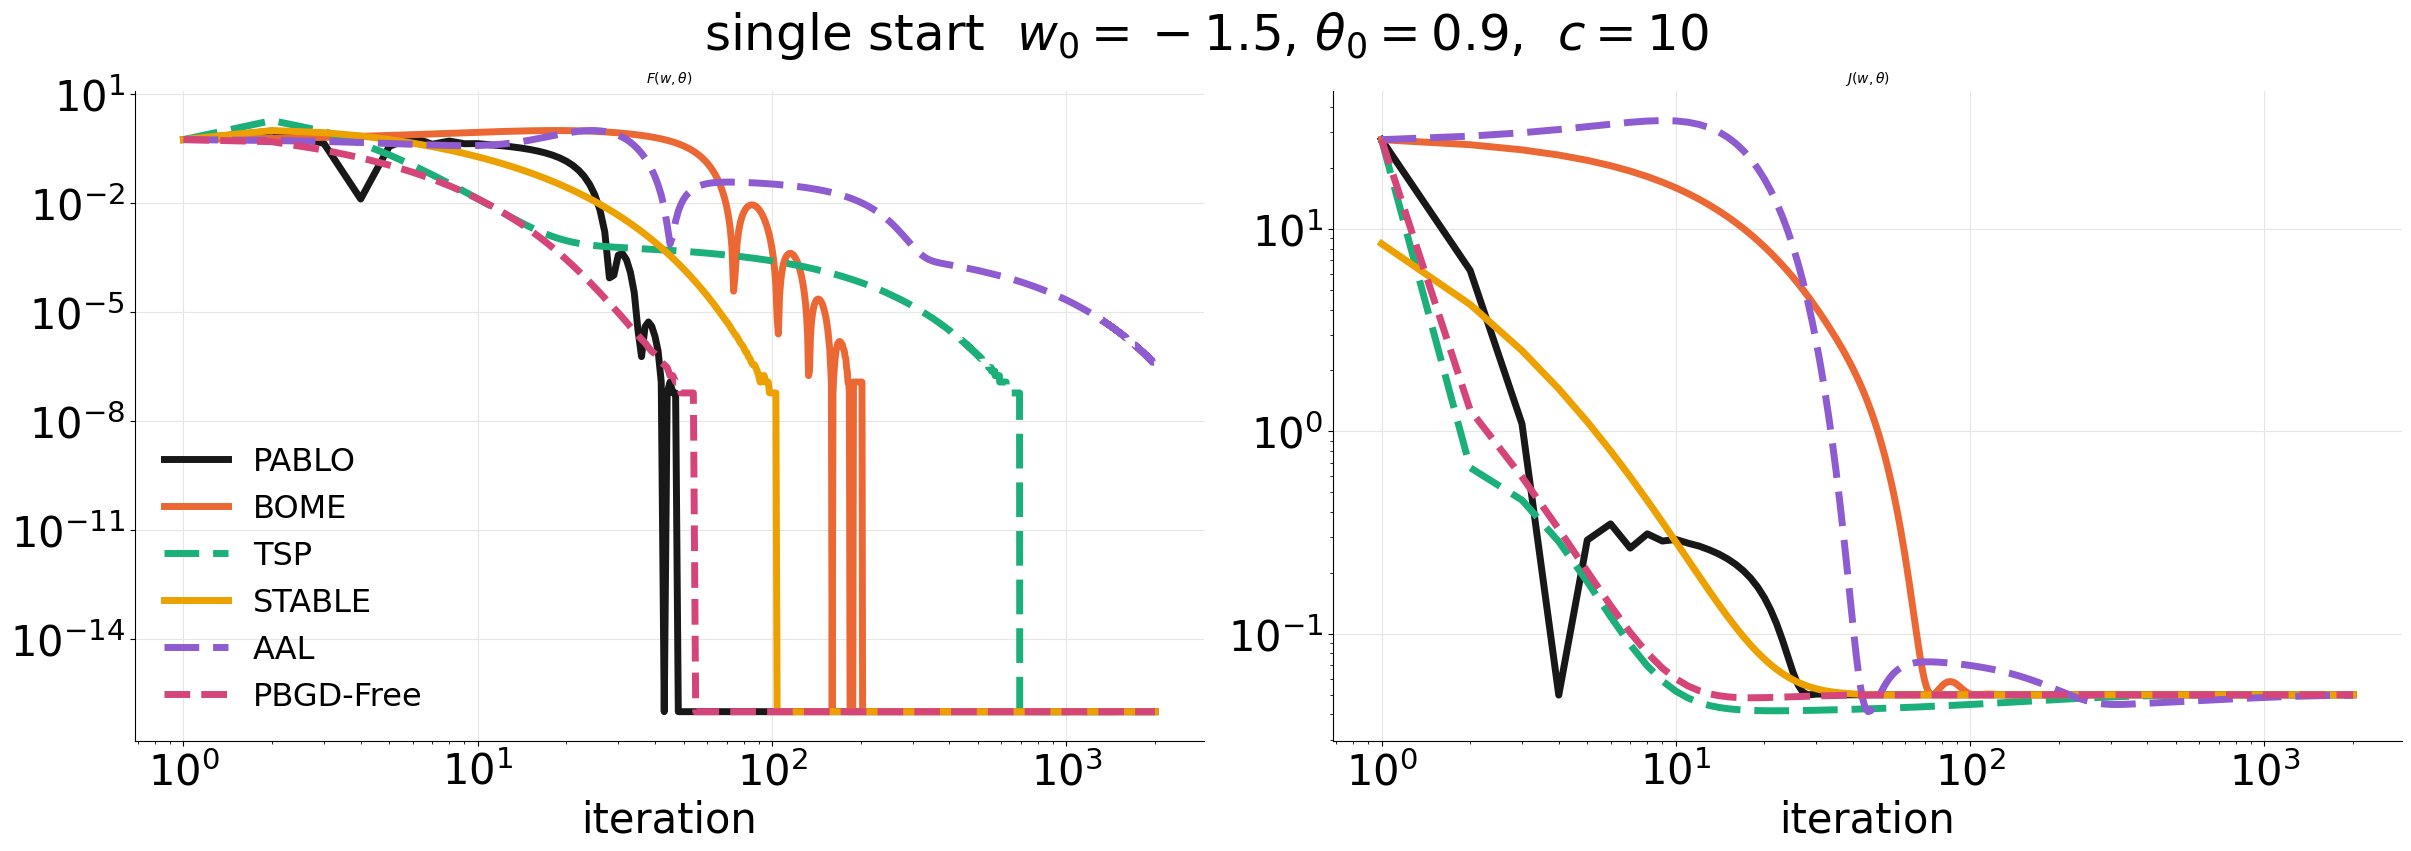

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(24, 8.4), constrained_layout=True)
plt.rcParams.update({'font.size': 30})

for ax, (key, title) in zip(axes, [("ul_loss", r"$F(w,\theta)$"), (("ll_loss", r"$J(w,\theta)$"))]):
    for m in METHODS:
        r = single[m]
        y = np.abs(r[key]) 
        ax.plot(np.arange(1, len(y) + 1), np.maximum(y, 1e-16),
                color=COLOURS[m],  linestyle=LINESTYLES[m], linewidth=5, label=m)
    ax.set_yscale("log"); ax.set_xlabel("iteration"); ax.set_title(title, fontsize=10)
    ax.grid(True, color="#e6e6e3", linewidth=0.8); ax.set_axisbelow(True)
    for s in ("top", "right"): ax.spines[s].set_visible(False)
axes[0].legend(frameon=False, fontsize=23)
fig.suptitle(f"single start  $w_0={W0}$, $\\theta_0={THETA0}$,  $c={C:g}$")
axes[0].set_xscale('log')
axes[1].set_xscale('log')
plt.show()

## Run the sweep

Uses all but one core. At the defaults this is a few hundred runs; the 20×20 / 2000-iteration
setting used in the report is ~1600 runs and takes a couple of minutes.

In [33]:
t0 = time.time()
sweep = run_sweep({m: HPARAMS[m] for m in METHODS},
                  c=C, grid_lo=GRID_LO, grid_hi=GRID_HI, grid_n=GRID_N,
                  n_iters=N_ITERS, seed=SEED, n_jobs=N_JOBS)
summary = summarise(sweep, tol=TOL, c=C)
print(f"\ndone in {time.time()-t0:.1f}s\n")
print(summary_table(summary, order=METHODS))

c = 10;  3x3 = 9 starts on [-1.5, 1.5]^2;  2000 iterations;  54 runs

done in 12.0s

method     solved  wrong basin  diverged   median |w-w*|      geomean  median theta err
--------------------------------------------------------------------------------------
PABLO       88.9%         0.0%      0.0%       1.373e-08    3.851e-11         0.000e+00
BOME        66.7%        33.3%      0.0%       4.633e-08    2.100e-08         0.000e+00
TSP        100.0%         0.0%      0.0%       6.422e-09    2.317e-11         2.498e-08
STABLE      66.7%        33.3%      0.0%       5.671e-08    2.247e-08         0.000e+00
AAL         55.6%         0.0%      0.0%       2.668e-07    2.471e-10         8.297e-04
PBGD-Free   100.0%         0.0%      0.0%       2.380e-08    4.134e-11         0.000e+00

fractions are over ALL starts; medians/geomeans over completed runs only


## Averaged results

* **left** — median $|w-w^\ast|$ across starts
* **middle** — median $\theta$ error across starts
* **right** — fraction of *all* starts solved to `TOL` by iteration $t$

Medians are over the runs that **completed**; the legend flags any method that lost starts to
divergence, since its median is then over a biased subset. The success-rate panel always uses
all starts as the denominator.

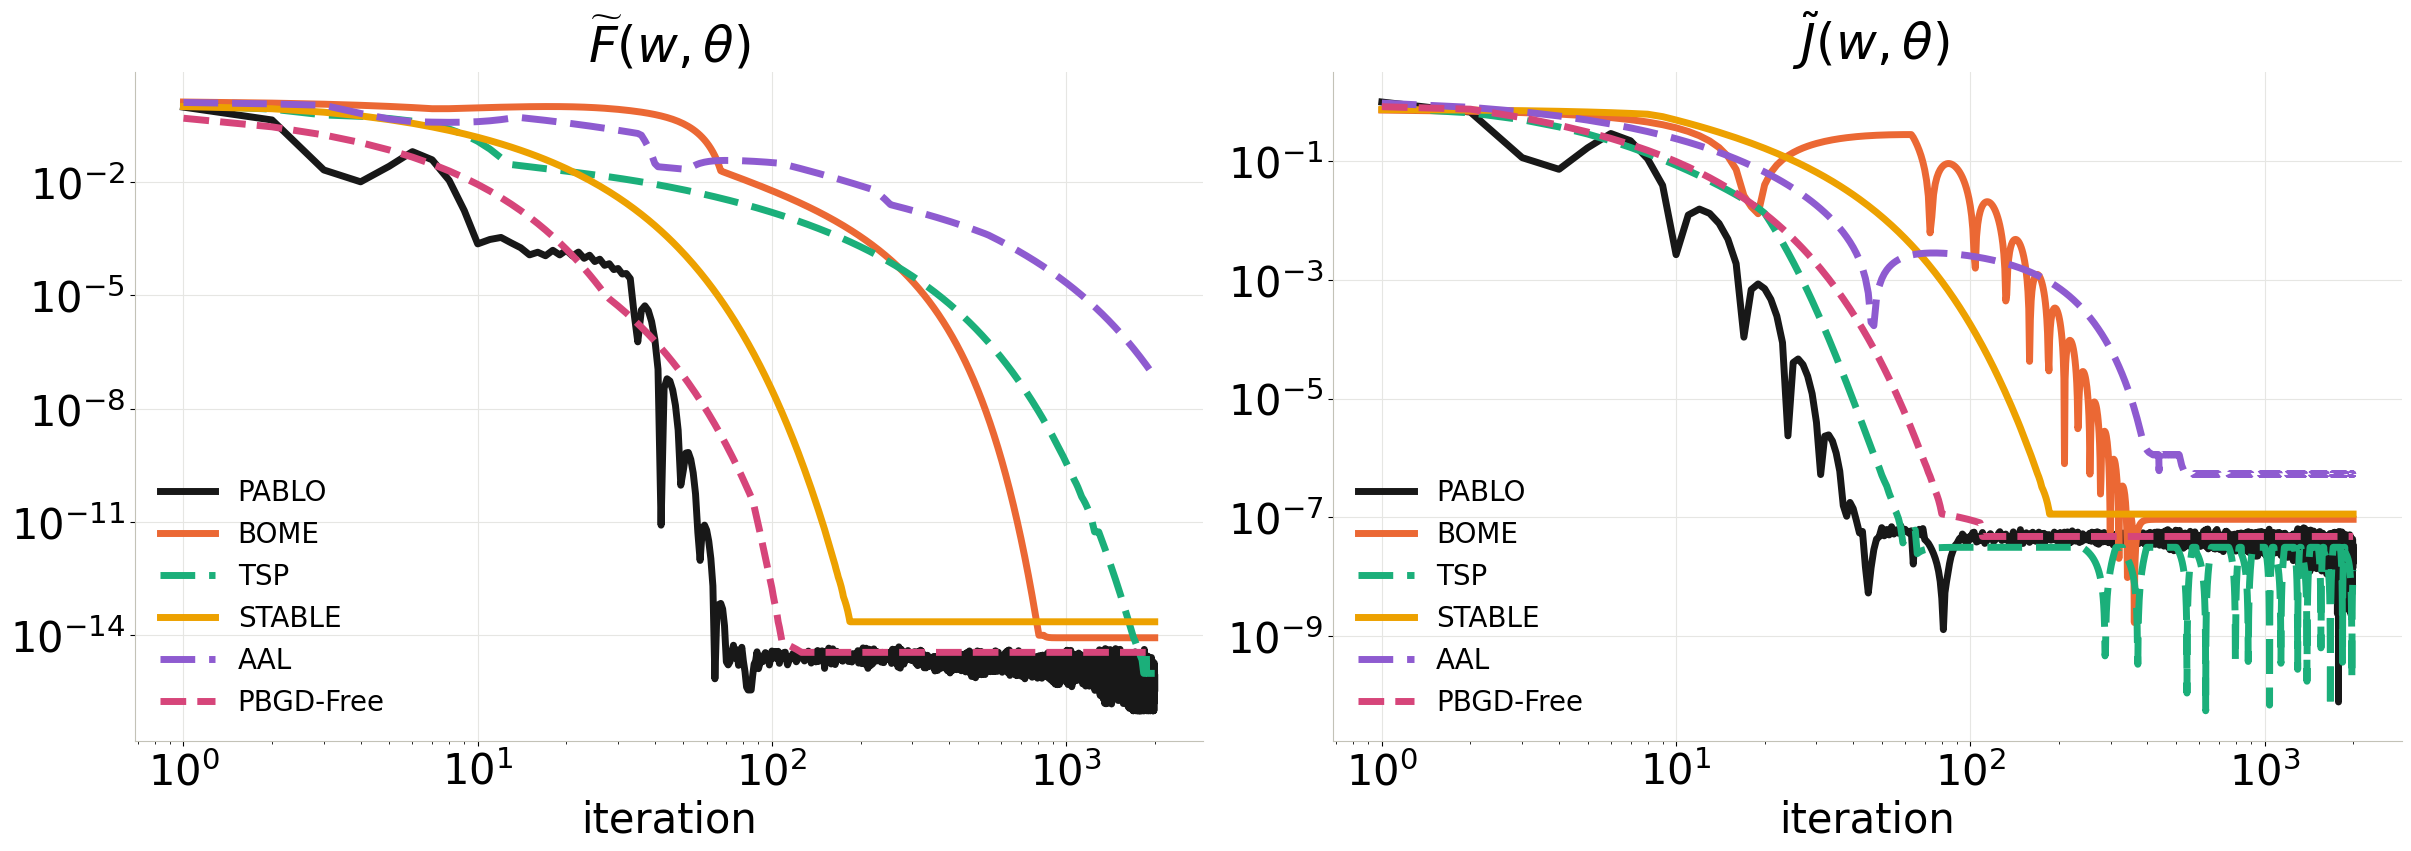

In [41]:
fig_sweep, axes = plt.subplots(1, 2, figsize=(24, 8.4), constrained_layout=True)
plt.rcParams.update({'font.size': 30})
for ax in axes:
    _style(ax)
# axes[2].set_yscale("linear")

it = np.arange(1, N_ITERS + 1)
ends = [[], []]
for m in METHODS:
    s = summary[m]
    if s["median_curve_w"] is None:
        print(f"{m}: every start diverged, nothing to plot")
        continue
    lbl = m if s["frac_completed"] > 0.999 else f"{m} ({s['frac_completed']*100:.0f}% of starts)"
    axes[0].plot(it, np.maximum(s["median_curve_UL_gap"], 1e-16), color=COLOURS[m],linestyle=LINESTYLES[m],linewidth=5,)
    axes[1].plot(it, np.maximum(s["median_curve_LL_gap"], 1e-16), color=COLOURS[m],linestyle=LINESTYLES[m], linewidth=5,)
    # axes[2].plot(it, s["success_curve"], color=COLOURS[m], linewidth=2, label=lbl)
    ends[0].append((m, max(s["median_curve_w"][-1], 1e-16), COLOURS[m]))
    ends[1].append((m, max(s["median_curve_theta"][-1], 1e-16), COLOURS[m]))

axes[0].set_title(r"$\widetilde{F}(w,\theta)$")
axes[1].set_title(r" $\widetilde{J}(w,\theta)$")
# axes[2].set_title(rf"fraction of starts with $|w-w^*| \leq$ {TOL:g}", fontsize=10)
# axes[2].set_ylim(-0.03, 1.03)

# for ax, bucket in zip(axes[:2], ends):
#     ax.set_xlim(1, N_ITERS * 1.34)
#     for label, y, colour in _place_labels(ax, bucket):
#         ax.annotate(label, xy=(N_ITERS * 1.04, y), fontsize=7.5, color="#3d3d38", va="center")
# axes[2].set_xlim(1, N_ITERS)
axes[0].legend(METHODS,frameon=False, fontsize=20,loc="lower left")
axes[1].legend(METHODS,frameon=False, fontsize=20, loc="lower left")

axes[0].set_xscale('log')
axes[1].set_xscale('log')
# axes[1].legend(frameon=False, fontsize=8, loc="upper right")

# fig_sweep.suptitle(f"Toy bilevel problem, $c={C:g}$ — averaged over a {GRID_N}$\\times${GRID_N} grid "
#              f"of starts $(w_0,\\theta_0)\\in[{GRID_LO},{GRID_HI}]^2$",
#              fontsize=11, color="#3d3d38")

plt.show()

In [42]:
# Helper function to crop and save an individual axis
def save_axis(ax, filepath, dpi=300):
    fig = ax.figure
    fig.canvas.draw()  # Force renderer to compute bounding boxes
    bbox = ax.get_tightbbox(fig.canvas.get_renderer()).transformed(fig.dpi_scale_trans.inverted())
    fig.savefig(filepath, bbox_inches=bbox, dpi=dpi)

# Save the two axes into separate files
save_axis(axes[0], f"{C}_UL_gap.png")   # or .jpg
save_axis(axes[1], f"{C}_LL_gap.png")   # or .jpg

plt.show()

## Where each start ends up

One panel per method over the $(w_0, \theta_0)$ plane: green = solved, orange = converged to the
wrong lower-level basin $w=2$, red = diverged. This is what the aggregate numbers are hiding.

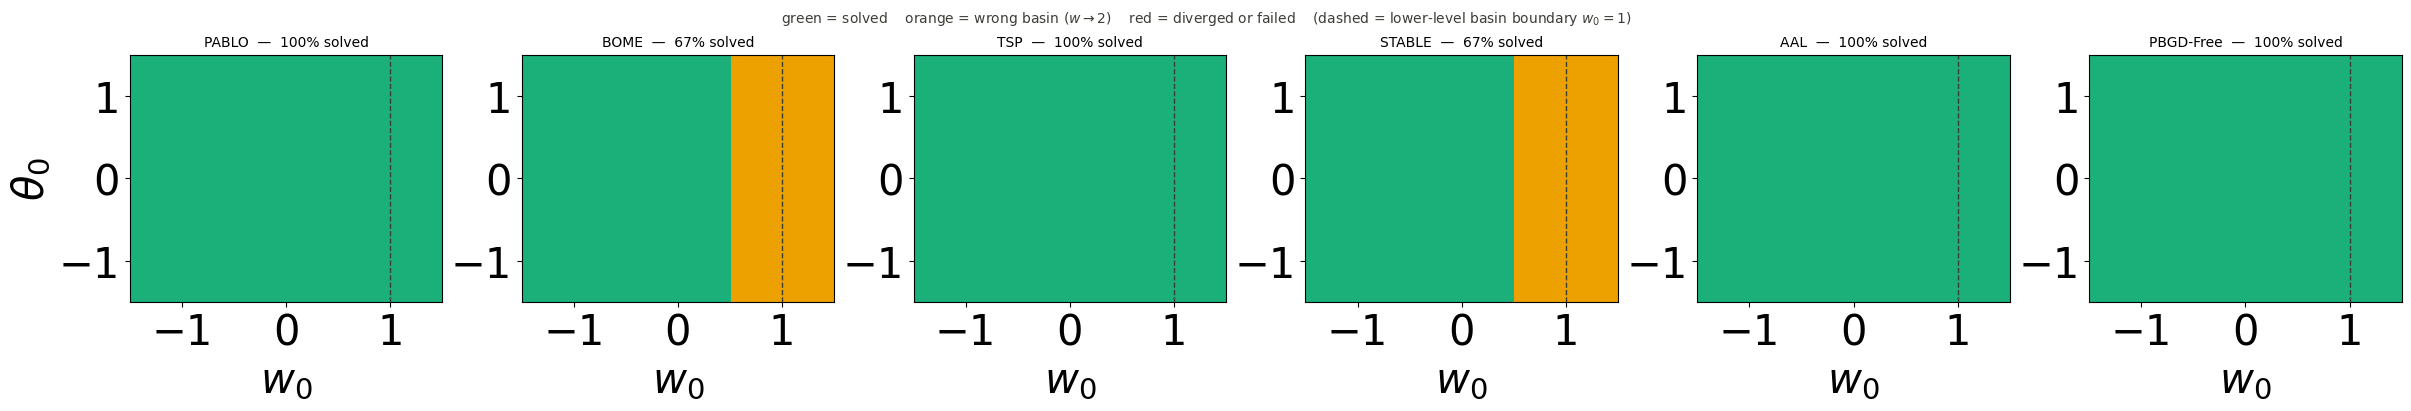

In [65]:
import matplotlib.colors as mcolors

# 0 = diverged or failed   1 = wrong lower-level basin (w -> 2)   2 = solved
fig_status, axes = plt.subplots(1, len(METHODS), figsize=(4 * len(METHODS), 4),
                                constrained_layout=True)
axes = np.atleast_1d(axes)
grid = np.linspace(GRID_LO, GRID_HI, GRID_N)
cmap = mcolors.ListedColormap(["#e34948", "#eda100", "#1baf7a"])

for ax, m in zip(axes, METHODS):
    status = np.zeros((GRID_N, GRID_N))                      # default: diverged/failed
    lookup = {st: k for k, st in enumerate(sweep[m]["starts"])}
    for i, w0 in enumerate(grid):
        for j, t0 in enumerate(grid):
            k = lookup.get((float(w0), float(t0)))
            if k is None:                                    # run diverged -> stays 0
                continue
            wf = float(sweep[m]["w"][k, -1])
            if abs(wf - W_STAR) <= TOL:
                status[j, i] = 2.0                           # solved
            elif abs(wf - 2.0) < 1e-3:
                status[j, i] = 1.0                           # wrong basin
            else:
                status[j, i] = 0.0                           # neither: failed to converge
    ax.imshow(status, origin="lower", cmap=cmap, vmin=0, vmax=2, aspect="auto",
              extent=[GRID_LO, GRID_HI, GRID_LO, GRID_HI])
    s = summary[m]
    ax.set_title(f"{m}  —  {s['frac_solved']*100:.0f}% solved", fontsize=10)
    ax.set_xlabel("$w_0$")
    ax.axvline(1.0, color="#3d3d38", linewidth=1, linestyle="--")   # basin boundary
axes[0].set_ylabel(r"$\theta_0$")
fig_status.suptitle("green = solved    orange = wrong basin ($w\\to2$)    "
                    "red = diverged or failed    "
                    "(dashed = lower-level basin boundary $w_0=1$)",
                    fontsize=10, color="#3d3d38")
plt.show()

## Save

Writes the figure, a per-start CSV and the exact hyperparameters used, so a run is reproducible.

In [9]:
import csv

os.makedirs("results", exist_ok=True)
tag = f"c{C:g}_n{GRID_N}_it{N_ITERS}"

fig_sweep.savefig(f"results/notebook_sweep_{tag}.png", dpi=160)
fig_status.savefig(f"results/notebook_sweep_{tag}_basins.png", dpi=160)

with open(f"results/notebook_sweep_{tag}.csv", "w", newline="") as fh:
    wr = csv.writer(fh)
    wr.writerow(["algorithm", "w0", "theta0", "final_w", "final_theta",
                 "final_w_err", "final_theta_err", "solved"])
    for m in METHODS:
        for (w0, t0), w, th in zip(sweep[m]["starts"], sweep[m]["w"], sweep[m]["theta"]):
            we = abs(float(w[-1]) - W_STAR)
            wr.writerow([m, w0, t0, float(w[-1]), float(th[-1]), we,
                         float(theta_error(th[-1])), int(we <= TOL)])

with open(f"results/notebook_sweep_{tag}_params.txt", "w") as fh:
    fh.write(f"c = {C}\ngrid = {GRID_N}x{GRID_N} on [{GRID_LO}, {GRID_HI}]^2\n"
             f"n_iters = {N_ITERS}\ntol = {TOL}\nseed = {SEED}\n\n")
    fh.write(json.dumps({m: HPARAMS[m] for m in METHODS}, indent=2, default=str))
    fh.write("\n\n" + summary_table(summary, order=METHODS) + "\n")

print(f"wrote results/notebook_sweep_{tag}.png / .csv / _params.txt")

wrote results/notebook_sweep_c10_n3_it800.png / .csv / _params.txt


<!-- ____
____

# Across Different values of c

<!--
=== TUNING CONSTANTS (coordinate-descent, _T_ITERS=2000, _T_N=5, grid [-2,2]^2, seed=0) ===

SCORING (method_score, defined in BOME cell):
    combined = max(median_curve_UL_gap, median_curve_LL_gap).clip(min=1e-16)
    auc      = sum(log10(combined))
    score    = auc + (1 - frac_solved) * 2e4
    → inf if any run diverged (frac_completed < 1)

─────────────────────────────────────────────────────
PABLO  (cell 0d2cd8e7)  c=[5]
  REF: lr=0.056234, alpha=0.999, eps=1e-6, rho=0.1, lr_lambda=0.5,
       tau=0.001, y_rate=1.880302, grad_clip=100.0, lambda_bound=10.0
  GRIDS (coord-descent order):
    lr        : logspace(0.01,   0.1,    n=8)
    lr_lambda : logspace(0.04,   0.1,    n=4)
    y_rate    : logspace(0.1,    5.0,    n=4)
    tau       : logspace(0.005,  0.1,    n=5)
    grad_clip : logspace(1,      100,    n=5)
    eps       : logspace(1e-9,   1,      n=5)

─────────────────────────────────────────────────────
BOME  (cell 2ae07341)  c=[0.1, 1, 5, 10, 50]
  REF: lr=0.03, opt="adam", inner_steps=10, inner_lr=0.01, eta=0.1, barrier="grad_norm"
  GRIDS:
    lr        : logspace(0.003,  0.3,    n=10)
    inner_lr  : logspace(0.001,  0.1,    n=10)
    eta       : logspace(0.01,   1.0,    n=10)

─────────────────────────────────────────────────────
TSP  (cell e32bf5f5)  c=[0.1, 1, 5, 10, 50]
  REF: gamma=0.2, delta=0.0, p=0.01, dual_tau=0.05, mu=0.5, theta=0.5,
       eta=0.01, step=0.04, omega=0.2, lambda_init=1.0
  GRIDS:
    eta       : logspace(0.001,  0.1,    n=10)
    step      : logspace(0.004,  0.4,    n=10)
    dual_tau  : logspace(0.005,  0.5,    n=10)
    omega     : logspace(0.02,   2.0,    n=10)

─────────────────────────────────────────────────────
STABLE  (cell be854aca)  c=[0.1, 1, 5, 10, 50]
  REF: lr_w=0.02, lr_theta=0.232079, tau=0.1, mu_g=0.01, C_gxy=1.0
  GRIDS:
    C_gxy     : logspace(1,      100,    n=10)
    lr_w      : logspace(0.001,  0.1,    n=10)
    lr_theta  : logspace(0.05,   5.0,    n=10)
    tau       : logspace(0.01,   10.0,   n=10)
    mu_g      : logspace(0.01,   1.0,    n=10)

─────────────────────────────────────────────────────
AAL  (cell fd64fa98)  c=[0.1, 1, 5, 10, 50]
  REF: L_f=71.0, L_grad_g=71.0, L_H=60.0, gamma=0.01, rho0=0.0,
       alpha=1e-5, eps=1e-5, tau=1e-3
  GRIDS:
    gamma     : logspace(0.001,  0.1,    n=10)
    alpha     : logspace(1e-6,   1e-4,   n=10)
    tau       : logspace(1e-4,   1e-2,   n=10)

─────────────────────────────────────────────────────
PBGD-Free  (cell ce9a75e7)  c=[0.1, 1, 5, 10, 50]
  REF: gamma=10.0, eta=0.05, eta_gamma=0.009, K=1
  GRIDS:
    gamma     : logspace(1,      100,    n=4)
    eta       : logspace(0.01,   0.1,    n=4)
    eta_gamma : logspace(0.001,  0.01,   n=4)
--> -->

In [ ]:
# HPARAMS_BY_C = {
#       0.1: {
#           "PABLO":     dict(lr=0.024495, alpha=0.999, eps=1e-6, rho=0.031623, lr_lambda=0.063246, tau=0.01, y_rate=1.880302, grad_clip=10.0, lambda_bound=1.0, total_steps=None),
#         "BOME":      dict(lr=0.107814, opt="adam", inner_steps=10, inner_lr=0.001, eta=0.215443, barrier="grad_norm"),
#         "TSP":       dict(gamma=0.2, delta=0.0, p=0.01, dual_tau=0.005, mu=0.5, theta=0.5, eta=0.01, step=0.004, omega=0.02, lambda_init=1.0),
#         "STABLE":    dict(lr_w=0.02, lr_theta=0.232079, tau=0.1, mu_g=0.01, C_gxy=10.0),
#         "AAL":       dict(L_f=71.0, L_grad_g=71.0, L_H=60.0, gamma=0.01, rho0=0.0, alpha=1e-5, eps=1e-5, tau=0.001),
#         "PBGD-Free": dict(gamma=10.0, eta=0.05, eta_gamma=0.009, K=1),
#     },
#       1.0: {
#           "PABLO":     dict(lr=0.056234, alpha=0.999, eps=1e-6, rho=0.1, lr_lambda=0.5, tau=0.001, y_rate=1.880302, grad_clip=100.0, lambda_bound=10.0, total_steps=None),
#         "BOME":      dict(lr=0.107814, opt="adam", inner_steps=10, inner_lr=0.001, eta=0.215443, barrier="grad_norm"),
#         "TSP":       dict(gamma=0.2, delta=0.0, p=0.01, dual_tau=0.023208, mu=0.5, theta=0.5, eta=0.059948, step=0.030971, omega=1.198969, lambda_init=1.0),
#         "STABLE":    dict(lr_w=0.02, lr_theta=0.05, tau=0.01, mu_g=0.01, C_gxy=10.0),
#         "AAL":       dict(L_f=71.0, L_grad_g=71.0, L_H=60.0, gamma=0.03593814, rho0=0.0, alpha=3.594e-5, eps=1e-5, tau=0.01),
#         "PBGD-Free": dict(gamma=1.0, eta=0.021544, eta_gamma=0.01, K=1),
#     },
#       5.0: {
#           "PABLO":     dict(lr=0.071969, alpha=0.999, eps=1e-9, rho=0.1, lr_lambda=0.1, tau=0.047287, y_rate=0.1, grad_clip=100.0, lambda_bound=10.0, total_steps=None),
#         "BOME":      dict(lr=0.107814, opt="adam", inner_steps=10, inner_lr=0.001, eta=0.215443, barrier="grad_norm"),
#         "TSP":       dict(gamma=0.2, delta=0.0, p=0.01, dual_tau=0.5, mu=0.5, theta=0.5, eta=0.059948, step=0.030971, omega=1.198969, lambda_init=1.0),
#         "STABLE":    dict(lr_w=0.021544, lr_theta=0.232079, tau=0.01, mu_g=0.01, C_gxy=10.0),
#         "AAL":       dict(L_f=71.0, L_grad_g=71.0, L_H=60.0, gamma=0.001, rho0=0.0, alpha=4.64e-6, eps=1e-5, tau=0.01),
#         "PBGD-Free": dict(gamma=1.0, eta=0.1, eta_gamma=0.01, K=1),
#     },
#       10.0: {
#           "PABLO":     dict(lr=0.031623, alpha=0.999, eps=1e-4, rho=0.1, lr_lambda=0.070711, tau=0.01, y_rate=0.265915, grad_clip=10.0, lambda_bound=10.0, total_steps=None),
#         "BOME":      dict(lr=0.107814, opt="adam", inner_steps=10, inner_lr=0.001, eta=0.215443, barrier="grad_norm"),
#         "TSP":       dict(gamma=0.2, delta=0.0, p=0.01, dual_tau=0.5, mu=0.5, theta=0.5, eta=0.059948, step=0.030971, omega=1.198969, lambda_init=1.0),
#         "STABLE":    dict(lr_w=0.021544, lr_theta=0.387132, tau=0.01, mu_g=0.01, C_gxy=10.0),
#         "AAL":       dict(L_f=71.0, L_grad_g=71.0, L_H=60.0, gamma=0.00464159, rho0=0.0, alpha=4.64e-6, eps=1e-5, tau=0.01),
#         "PBGD-Free": dict(gamma=1.0, eta=0.1, eta_gamma=0.01, K=1),
#     },
#       50.0: {
#           "PABLO":     dict(lr=0.031623, alpha=0.999, eps=1e-4, rho=0.1, lr_lambda=0.070711, tau=0.01, y_rate=0.265915, grad_clip=10.0, lambda_bound=10.0, total_steps=None),  # not tuned — using c=10 values
#           "BOME":      dict(lr=0.107814, opt="adam", inner_steps=10, inner_lr=0.001, eta=0.215443, barrier="grad_norm"),
#         "TSP":       dict(gamma=0.2, delta=0.0, p=0.01, dual_tau=0.5, mu=0.5, theta=0.5, eta=0.059948, step=0.030971, omega=1.198969, lambda_init=1.0),
#         "STABLE":    dict(lr_w=0.021544, lr_theta=1.796907, tau=0.01, mu_g=0.01, C_gxy=10.0),
#         "AAL":       dict(L_f=71.0, L_grad_g=71.0, L_H=60.0, gamma=0.001, rho0=0.0, alpha=4.64e-6, eps=1e-5, tau=0.002154),
#         "PBGD-Free": dict(gamma=1.0, eta=0.1, eta_gamma=0.01, K=1),
#     },
#   }


# Claude tuned
# 0.1:  "PBGD-Free": dict(gamma=0.5, eta=0.00243, eta_gamma=0.012, K=1),
# 1.0:  "PBGD-Free": dict(gamma=0.5, eta=0.0243,  eta_gamma=0.012, K=1),
# 5.0:  "PBGD-Free": dict(gamma=0.5, eta=0.1215,  eta_gamma=0.012, K=1),
# 10.0: "PBGD-Free": dict(gamma=0.5, eta=0.243,   eta_gamma=0.012, K=1),
# 50.0: "PBGD-Free": dict(gamma=0.5, eta=1.215,   eta_gamma=0.012, K=1),

# 0.1:        "TSP": dict(gamma=0.2, delta=0.0, p=0.01, dual_tau=0.05, mu=0.5, theta=0.5, eta=0.015, step=0.008, omega=0.2, lambda_init=1.0),
# 1, 5, 10, 50: "TSP": dict(gamma=0.2, delta=0.0, p=0.01, dual_tau=0.05, mu=0.5, theta=0.5, eta=0.01,  step=0.04,  omega=0.2, lambda_init=1.0),
# 0.1:  "STABLE": dict(lr_w=0.02,     lr_theta=0.00702,  tau=0.1,  mu_g=0.01, C_gxy=10.0),
# 1.0:  "STABLE": dict(lr_w=0.02,     lr_theta=0.075,    tau=0.01, mu_g=0.01, C_gxy=10.0),
# 5.0:  "STABLE": dict(lr_w=0.021544, lr_theta=0.348118, tau=0.01, mu_g=0.01, C_gxy=10.0),
# 10.0: "STABLE": dict(lr_w=0.01,     lr_theta=0.75,     tau=1.0,  mu_g=0.1,  C_gxy=10.0),
# 50.0: "STABLE": dict(lr_w=0.021544, lr_theta=3.593814, tau=0.01, mu_g=0.01, C_gxy=10.0),

#  ───────────┬───────────┬────────────┬────────────────────┬───────────────────────────┐    
# │  Method   │  Total    │   Total    │      ms/iter       │ Avg wall-clock per sweep  │    
# │           │   runs    │   iters    │    (wall-clock)    │            (s)            │    
# ├───────────┼───────────┼────────────┼────────────────────┼───────────────────────────┤    
# │ PABLO     │ 776       │ 1,552,000  │ 0.146              │ 6.67                      │    
# ├───────────┼───────────┼────────────┼────────────────────┼───────────────────────────┤    
# │ BOME      │ 3,751     │ 7,502,000  │ 0.277              │ 13.63                     │    
# ├───────────┼───────────┼────────────┼────────────────────┼───────────────────────────┤    
# │ TSP       │ 5,001     │ 10,002,000 │ 0.137              │ 6.78                      │    
# ├───────────┼───────────┼────────────┼────────────────────┼───────────────────────────┤    
# │ STABLE    │ 6,251     │ 12,502,000 │ 0.136              │ 6.72                      │    
# ├───────────┼───────────┼────────────┼────────────────────┼───────────────────────────┤    
# │ AAL       │ 3,751     │ 7,502,000  │ 0.159              │ 7.84                      │    
# ├───────────┼───────────┼────────────┼────────────────────┼───────────────────────────┤
# │ PBGD-Free │ 1,501     │ 3,002,000  │ 0.087              │ 4.23                      │    
# └───────────┴───────────┴────────────┴────────────────────┴───────────────────────────┘

In [1]:
import os, sys, json, time
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, "experiments")
import toy_lib
from toy_lib import run_single, run_sweep, summarise, summary_table, theta_error, W_STAR

%load_ext autoreload
%autoreload 2

print("methods:", toy_lib.METHODS)
print("cpu count:", os.cpu_count())
COLOURS = {"PABLO": "#181818", "BOME": "#eb6834", "TSP": "#1baf7a", "STABLE": "#eda100",
           "AAL": "#8e5bd0", "PBGD-Free": "#d6457a"}
LINESTYLES = {"PABLO": "-", "BOME": "-", "STABLE": "-",
              "TSP": (0, (5, 2)), "AAL": (0, (5, 2)), "PBGD-Free": "--"}

def _style(ax, logy=True):
    if logy:
        ax.set_yscale("log")
    ax.set_xlabel("iteration")
    ax.grid(True, which="major", color="#e6e6e3", linewidth=0.8)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color("#c3c2b7")

def _place_labels(ax, entries):
    """Greedy de-collision of end-of-line labels in log space."""
    lo, hi = np.log10(ax.get_ylim()[0]), np.log10(ax.get_ylim()[1])
    gap = (hi - lo) * 0.06
    placed, prev = [], -np.inf
    for name, y, colour in sorted(entries, key=lambda e: e[1]):
        ly = max(np.log10(max(y, 10 ** lo)), prev + gap)
        placed.append((name, 10 ** ly, colour))
        prev = ly
    return placed

methods: ['PABLO', 'BOME', 'TSP', 'STABLE', 'AAL', 'PBGD-Free']
cpu count: 8


In [ ]:

# ── Hardcoded hyperparameters per c value ─────────────────────────────────────
HPARAMS_BY_C = {
    0.1: {
        # "PABLO": dict(lr=0.024495, alpha=0.999, eps=1e-6, rho=0.031623,  lr_lambda=0.063246, tau=0.01, y_rate=1.880302, grad_clip=10.0,lambda_bound=1.0, total_steps=None),    
        "PABLO":    dict(lr=0.02, alpha=0.999, eps=1e-4, rho=0.1, lr_lambda=0.05, tau=0.01, y_rate=0.3, grad_clip=10.0,lambda_bound=10.0,),
        "BOME":      dict(lr=0.3, opt="adam", inner_steps=10, inner_lr=0.001, eta=0.1, barrier="grad_norm"),
        "TSP": dict(gamma=0.2, delta=0.0, p=0.01, dual_tau=0.05, mu=0.5, theta=0.5, eta=0.015, step=0.008, omega=0.2, lambda_init=1.0),
        "STABLE": dict(lr_w=0.02,     lr_theta=0.00702,  tau=0.1,  mu_g=0.01, C_gxy=10.0),
        "AAL":       dict(L_f=71.0, L_grad_g=71.0, L_H=60.0, gamma=0.01,        rho0=0.0, alpha=1e-5,     eps=1e-5, tau=0.001),
        "PBGD-Free": dict(gamma=0.5, eta=0.00243, eta_gamma=0.012, K=1),
    },
    1.0: {
        "PABLO":    dict(lr=0.05, alpha=0.999, eps=1e-4, rho=0.1, lr_lambda=0.05, tau=0.01, y_rate=0.3, grad_clip=10.0,lambda_bound=10.0,),                              
        "BOME":      dict(lr=0.3, opt="adam", inner_steps=10, inner_lr=0.001, eta=0.1, barrier="grad_norm"),
        "TSP": dict(gamma=0.2, delta=0.0, p=0.01, dual_tau=0.05, mu=0.5, theta=0.5, eta=0.01,  step=0.04,  omega=0.2, lambda_init=1.0),
        "STABLE": dict(lr_w=0.02,     lr_theta=0.075,    tau=0.01, mu_g=0.01, C_gxy=10.0),
        "AAL":       dict(L_f=71.0, L_grad_g=71.0, L_H=60.0, gamma=0.03593814, rho0=0.0, alpha=3.594e-5,  eps=1e-5, tau=0.01),
        "PBGD-Free": dict(gamma=0.5, eta=0.0243,  eta_gamma=0.012, K=1),
    },
    5.0: {
        # "PABLO": dict(lr=0.056234, alpha=0.999, eps=1e-6, rho=0.1,lr_lambda=0.5, tau=0.001, y_rate=1.880302, grad_clip=100.0, lambda_bound=10.0, total_steps=None),                              
        "PABLO":    dict(lr=0.05, alpha=0.999, eps=1e-4, rho=0.1, lr_lambda=0.05, tau=0.01, y_rate=0.3, grad_clip=10.0,lambda_bound=10.0,),
        "BOME":      dict(lr=0.3, opt="adam", inner_steps=10, inner_lr=0.001, eta=0.1, barrier="grad_norm"),
        "TSP": dict(gamma=0.2, delta=0.0, p=0.01, dual_tau=0.05, mu=0.5, theta=0.5, eta=0.01,  step=0.04,  omega=0.2, lambda_init=1.0),
        "STABLE": dict(lr_w=0.021544, lr_theta=0.348118, tau=0.01, mu_g=0.01, C_gxy=10.0),
        "AAL":       dict(L_f=71.0, L_grad_g=71.0, L_H=60.0, gamma=0.03593814, rho0=0.0, alpha=3.594e-5,  eps=1e-5, tau=0.01),
        "PBGD-Free": dict(gamma=0.5, eta=0.1215,  eta_gamma=0.012, K=1),
    },
    10.0: {
        "PABLO":    dict(lr=0.05, alpha=0.999, eps=1e-4, rho=0.1, lr_lambda=0.05, tau=0.01, y_rate=0.3, grad_clip=10.0,lambda_bound=10.0,),   
        "BOME":      dict(lr=0.3, opt="adam", inner_steps=10, inner_lr=0.001, eta=0.1, barrier="grad_norm"),
        "TSP": dict(gamma=0.2, delta=0.0, p=0.01, dual_tau=0.05, mu=0.5, theta=0.5, eta=0.01,  step=0.04,  omega=0.2, lambda_init=1.0),
        "STABLE": dict(lr_w=0.01,     lr_theta=0.75,     tau=1.0,  mu_g=0.1,  C_gxy=10.0),
        "AAL":       dict(L_f=71.0, L_grad_g=71.0, L_H=60.0, gamma=0.001,       rho0=0.0, alpha=1.292e-5, eps=1e-5, tau=1e-4),
        "PBGD-Free": dict(gamma=0.5, eta=0.243,   eta_gamma=0.012, K=1),
        },
    50.0: {
        "PABLO":    dict(lr=0.05, alpha=0.999, eps=1e-4, rho=0.1, lr_lambda=0.05, tau=0.01, y_rate=0.3, grad_clip=10.0,lambda_bound=10.0,),  
        "BOME":      dict(lr=0.3, opt="adam", inner_steps=10, inner_lr=0.001, eta=0.1, barrier="grad_norm"),
        "TSP": dict(gamma=0.2, delta=0.0, p=0.01, dual_tau=0.05, mu=0.5, theta=0.5, eta=0.01,  step=0.04,  omega=0.2, lambda_init=1.0),
        "STABLE":    dict(lr_w=0.021544, lr_theta=3.593814, tau=0.01, mu_g=0.01, C_gxy=10.0),
        "AAL":       dict(L_f=71.0, L_grad_g=71.0, L_H=60.0, gamma=0.001, rho0=0.0, alpha=4.64e-6, eps=1e-5, tau=0.002154),
        "PBGD-Free": dict(gamma=0.5, eta=1.215,   eta_gamma=0.012, K=1),
    },
    100.0: {
        "PABLO":    dict(lr=0.05, alpha=0.999, eps=1e-4, rho=0.1, lr_lambda=0.05, tau=0.01, y_rate=0.3, grad_clip=10.0,lambda_bound=10.0,),
        "BOME":      dict(lr=0.6, opt="adam", inner_steps=10, inner_lr=0.001, eta=0.5, barrier="grad_norm"),
        "TSP":       dict(gamma=0.2, delta=0.0, p=0.01, dual_tau=0.05, mu=0.5, theta=0.5, eta=0.015, step=0.04, omega=0.2, lambda_init=1.0),
        "STABLE":    dict(lr_w=0.021544, lr_theta=7.29, tau=0.01, mu_g=0.01, C_gxy=10.0),
        "AAL":       dict(L_f=71.0, L_grad_g=71.0, L_H=60.0, gamma=0.001, rho0=0.0, alpha=1e-6, eps=1e-5, tau=0.01),
        "PBGD-Free": dict(gamma=0.5, eta=5.4, eta_gamma=0.017, K=1),
    },
}

HPARAMS_BY_C[45] = HPARAMS_BY_C[50]
HPARAMS_BY_C[2] = HPARAMS_BY_C[1]
HPARAMS_BY_C[6] = HPARAMS_BY_C[5]
HPARAMS_BY_C[0.9] = HPARAMS_BY_C[1]
HPARAMS_BY_C[12] = HPARAMS_BY_C[10]
HPARAMS_BY_C[0.2] = HPARAMS_BY_C[0.1]

# _C_VALUES = [0.1, 0.2, 1, 2, 5, 6, 10.0, 12, 45, 50 ]
_C_VALUES = [0.1, 1,2,5,10,50]
_SEEDS    = [0]
_GRID_LO, _GRID_HI = -1.5, 1.5
_GRID_N   = 3
_N_ITERS  = 1000
_TOL      = 1e-6
_N_JOBS   = max(1, (os.cpu_count() or 2) - 1)
_METHODS  = ["PABLO", "BOME", "TSP", "STABLE", "AAL", "PBGD-Free"]

# ── Run sweeps: 3 seeds × 3 c-values ─────────────────────────────────────────
all_summaries_c = {}   # all_summaries_c[c][seed] = summary dict
all_sweeps_c    = {}

print(_C_VALUES)
for c in [0.1]:#_C_VALUES:
    all_summaries_c[c] = {}
    all_sweeps_c[c]    = {}
    hp = HPARAMS_BY_C[c]
    for seed in _SEEDS:
        t0 = time.time()
        sw = run_sweep({m: hp[m] for m in _METHODS}, c=c,
                       grid_lo=_GRID_LO, grid_hi=_GRID_HI, grid_n=_GRID_N,
                       n_iters=_N_ITERS, seed=seed, n_jobs=_N_JOBS)
        all_sweeps_c[c][seed]    = sw
        all_summaries_c[c][seed] = summarise(sw, tol=_TOL, c=c)
        print(f"c={c:g}, seed={seed}  done in {time.time()-t0:.1f}s")
    print(f"\n--- c={c:g} summary (seed 0) ---")
    print(summary_table(all_summaries_c[c][0], order=_METHODS))
    # print(summary_table(all_summaries_c[c][0]))
    print()

print("All sweeps done!")


[0.1, 1, 2, 5, 10, 50]
c = 0.1;  3x3 = 9 starts on [-1.5, 1.5]^2;  1000 iterations;  54 runs
c=0.1, seed=0  done in 14.5s

--- c=0.1 summary (seed 0) ---
method     solved  wrong basin  diverged   median |w-w*|      geomean  median theta err
--------------------------------------------------------------------------------------
PABLO       77.8%         0.0%      0.0%       3.146e-08    1.310e-10         0.000e+00
BOME       100.0%         0.0%      0.0%       3.668e-08    5.191e-11         0.000e+00
TSP        100.0%         0.0%      0.0%       2.110e-08    4.796e-11         1.788e-07
STABLE      66.7%        33.3%      0.0%       5.499e-08    2.224e-08         1.788e-07
AAL         44.4%         0.0%     33.3%       2.659e-07    2.470e-10         5.960e-08
PBGD-Free   100.0%         0.0%      0.0%       2.125e-08    3.935e-11         4.754e-23

fractions are over ALL starts; medians/geomeans over completed runs only

All sweeps done!


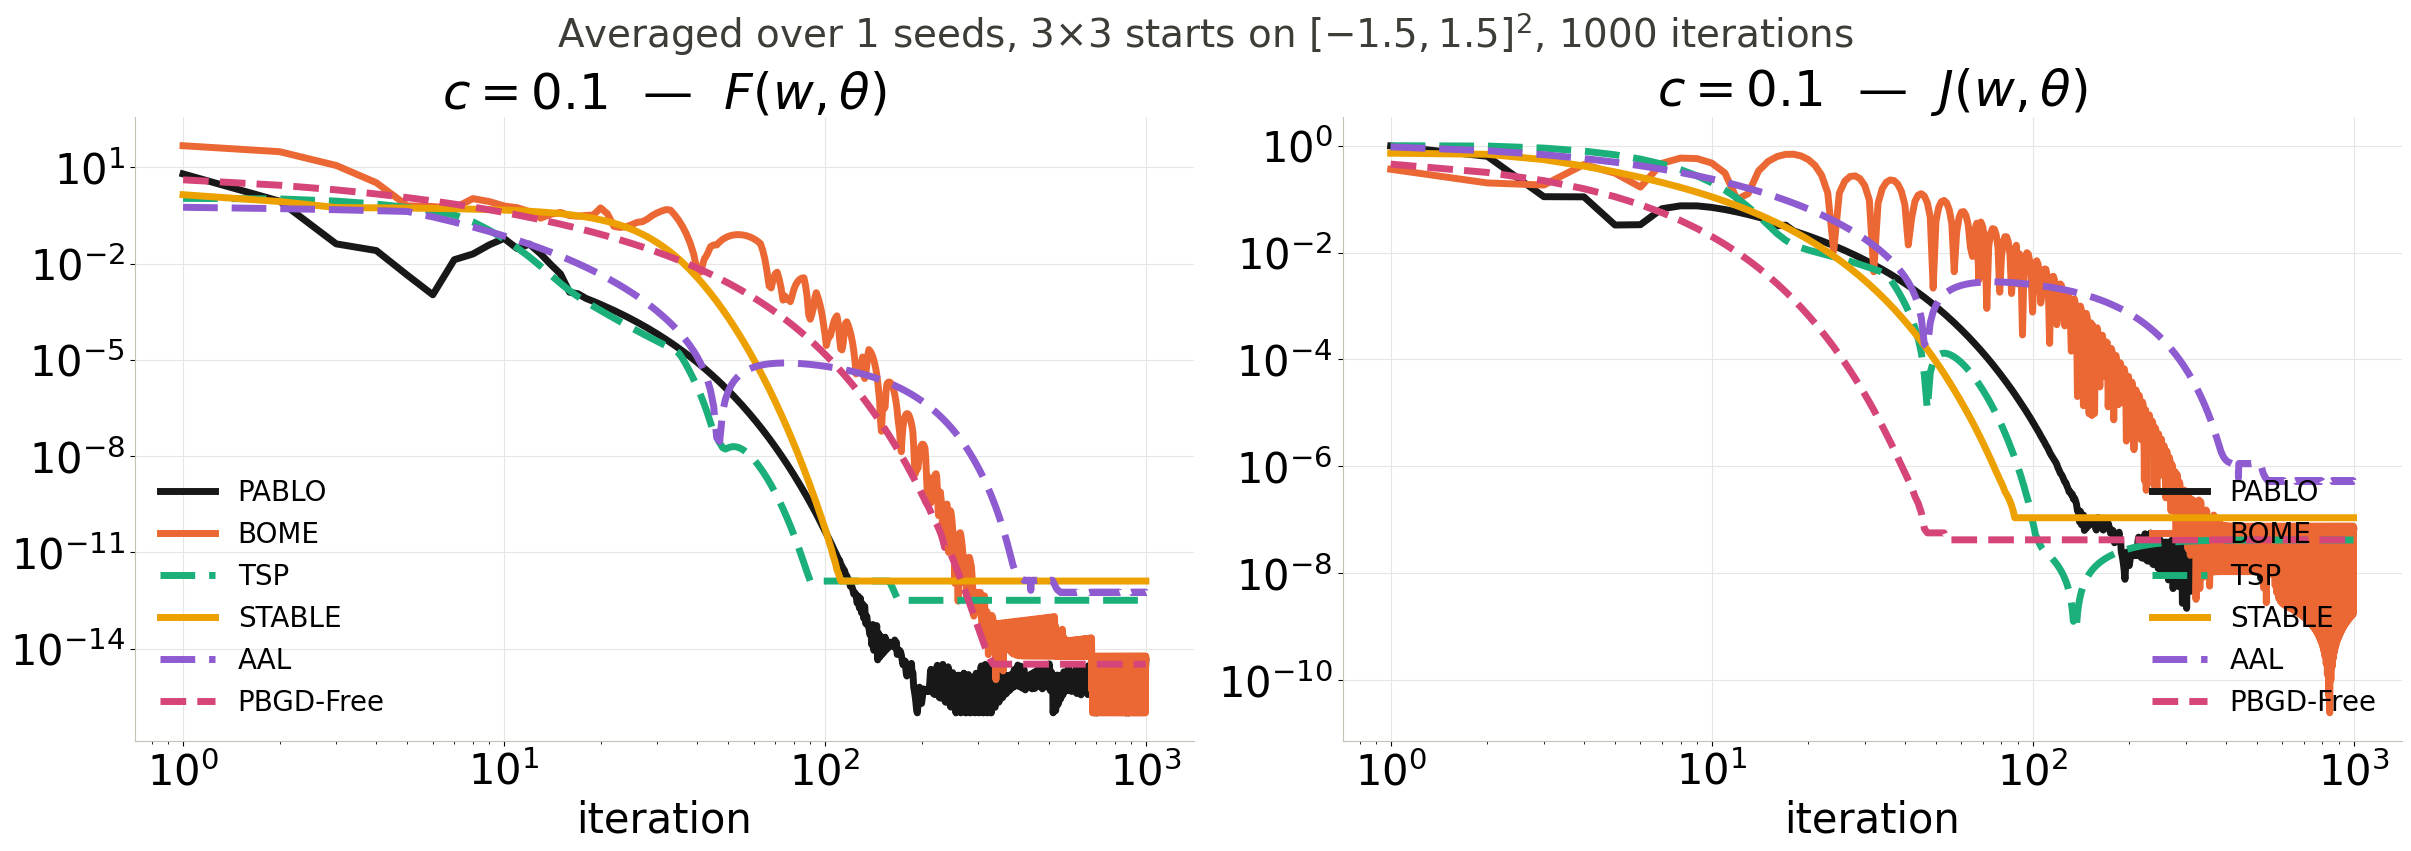

KeyError: 1

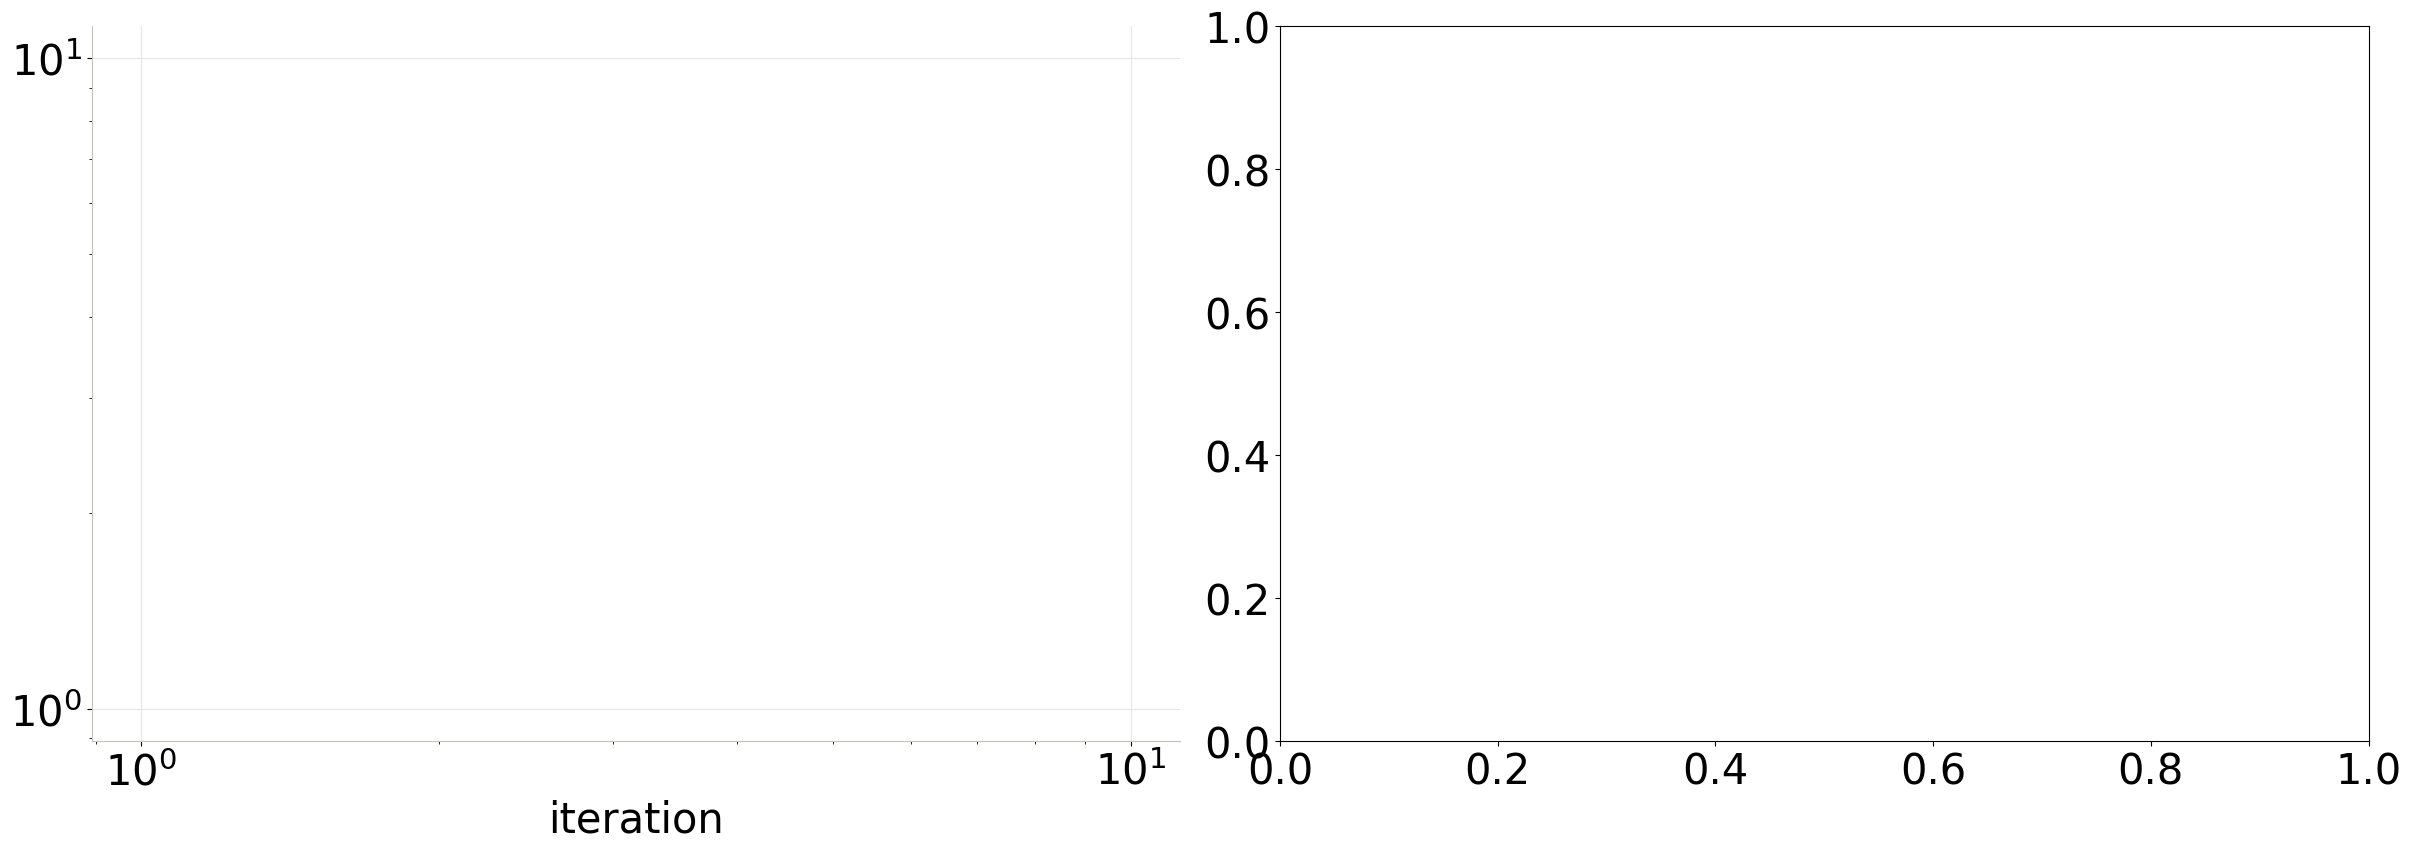

In [110]:

# ── Plot: 3 rows (one per c), 2 cols (F and J), curves averaged across seeds ──
plt.rcParams.update({'font.size': 30})

it = np.arange(1, _N_ITERS + 1)

for row, c in enumerate(_C_VALUES):
    fig_c, axes_c = plt.subplots(1, 2, figsize=(24, 8.4 ), constrained_layout=True)

    for col, (key, title) in enumerate([("median_curve_UL_gap", r"$F(w,\theta)$"),
                                         ("median_curve_LL_gap", r"$J(w,\theta)$")]):
        ax = axes_c[col]
        _style(ax)
        ax.set_xscale("log")
        for m in _METHODS:
            curves = []
            for seed in _SEEDS:
                s = all_summaries_c[c][seed][m]
                if s.get(key) is not None:
                    curves.append(np.maximum(s[key], 1e-16))
            if not curves:
                continue
            avg_curve = np.mean(curves, axis=0)
            ax.plot(it, avg_curve, color=COLOURS[m], linestyle=LINESTYLES[m], linewidth=5, label=m)
        ax.set_title(f"$c={c:g}$  —  {title}")
        loc = "lower left" if col == 0 else "lower right"
        ax.legend(frameon=False, fontsize=20, loc=loc)

    fig_c.suptitle(
        f"Averaged over {len(_SEEDS)} seeds, {_GRID_N}×{_GRID_N} starts on "
        f"$[{_GRID_LO},{_GRID_HI}]^2$, {_N_ITERS} iterations",
        fontsize=28, color="#3d3d38"
    )
    plt.show()


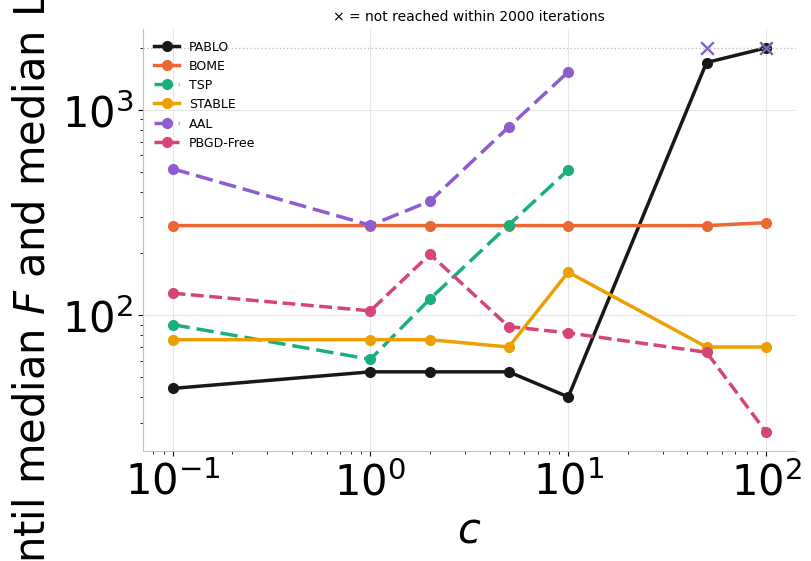

In [104]:
EPS = 1e-6           # target for both median curves
STAY = True           # True: first iteration after which BOTH stay below EPS
                      # False: first iteration at which both are below EPS

def iters_to_eps(ul, ll, eps=EPS, stay=STAY):
    """1-based iteration count, or np.nan if the target is never reached."""
    ok = (np.asarray(ul) <= eps) & (np.asarray(ll) <= eps)
    if not ok.any():
        return np.nan
    if not stay:
        return int(np.argmax(ok)) + 1
    # if not ok[-1]:                       # ended above eps -> not converged
    #     return np.nan
    bad = np.flatnonzero(~ok)
    return 1 if bad.size == 0 else int(bad[-1]) + 2

# ── collect: rows = c, one value per seed ─────────────────────────────────────
c_vals = sorted(all_summaries_c)
iters  = {m: np.full((len(c_vals), len(_SEEDS)), np.nan) for m in _METHODS}

for i, c in enumerate(c_vals):
    for j, seed in enumerate(_SEEDS):
        for m in _METHODS:
            s = all_summaries_c[c][seed][m]
            if s.get("median_curve_UL") is None:          # every start diverged
                continue
            iters[m][i, j] = iters_to_eps(s["median_curve_UL_gap"], s["median_curve_LL_gap"])

# ── plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 5.5), constrained_layout=True)
_style(ax)                     # log y
ax.set_xscale("log")
ax.set_xlabel("$c$")
ax.set_ylabel(rf"iterations until median $F$ and median LL gap $\leq$ {EPS:g}")

for m in _METHODS:
    vals = iters[m]
    reached = np.isfinite(vals)
    med = np.array([np.median(r[np.isfinite(r)]) if np.isfinite(r).any() else np.nan
                    for r in vals])
    lo  = np.array([np.min(r[np.isfinite(r)])    if np.isfinite(r).any() else np.nan
                    for r in vals])
    hi  = np.array([np.max(r[np.isfinite(r)])    if np.isfinite(r).any() else np.nan
                    for r in vals])

    ax.plot(c_vals, lo, color=COLOURS[m], linestyle=LINESTYLES[m],
            marker="o", linewidth=2.5, markersize=7, label=m)
    if len(_SEEDS) > 1:        # spread across seeds
        ax.fill_between(c_vals, lo, hi, color=COLOURS[m], alpha=0.15, linewidth=0)

    # mark c values where this method never got there (on any seed)
    never = ~reached.any(axis=1)
    if never.any():
        ax.scatter(np.array(c_vals)[never], np.full(never.sum(), _N_ITERS),
                   marker="x", s=80, color=COLOURS[m], zorder=5)

ax.axhline(_N_ITERS, color="#c3c2b7", linewidth=1, linestyle=":")
ax.legend(frameon=False, fontsize=9)
ax.set_title(f"× = not reached within {_N_ITERS} iterations", fontsize=10)
plt.show()

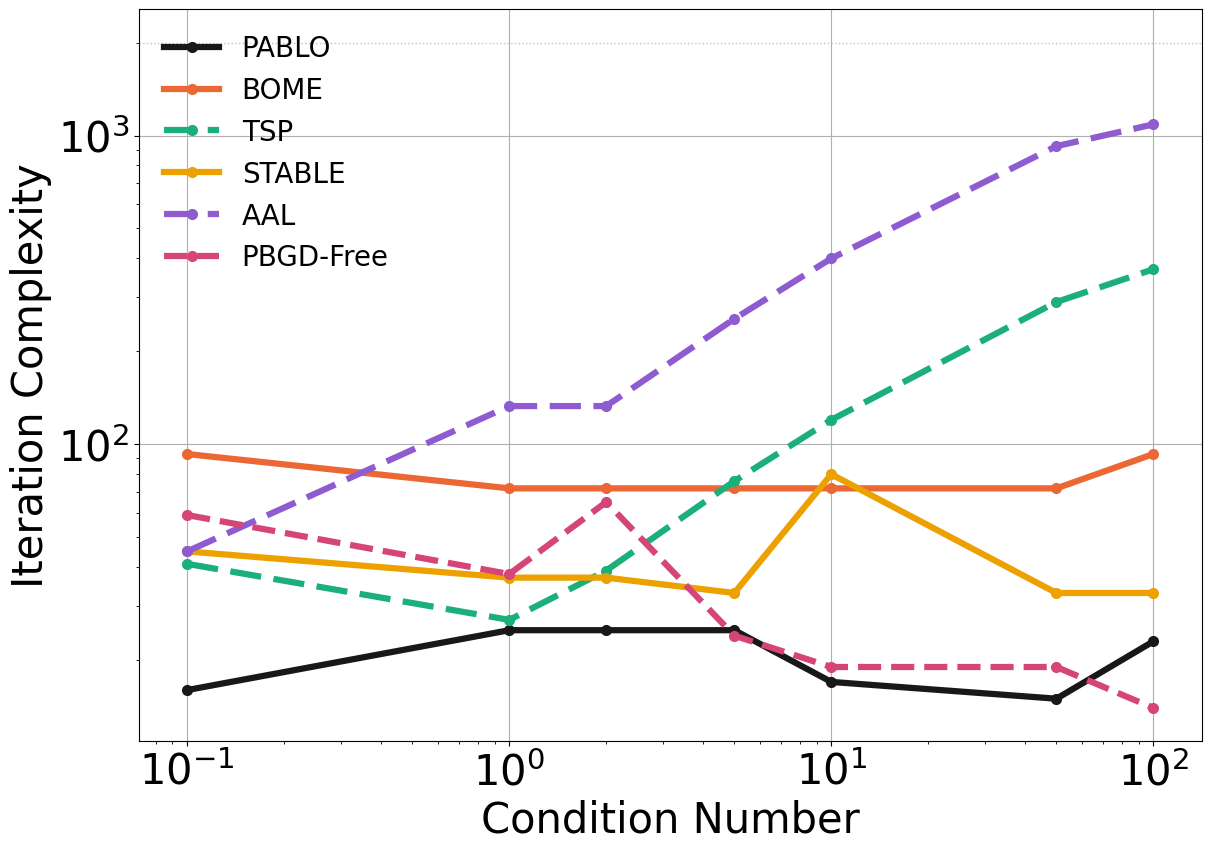

In [105]:
EPS = 1e-3
def iters_to_eps(ul, ll, eps=EPS, stay=False):
    """1-based iteration count, or np.nan if the target is never reached."""
    ok = (np.asarray(ul) <= eps) & (np.asarray(ll) <= eps)
    if not ok.any():
        return np.nan
    return ok*1
    # return 1 if bad.size == 0 else int(bad[-1]) + 2


comps = {}
for m in METHODS:
    comps[m] = comps.get(m,[])
    for c in c_vals:
        s = all_summaries_c[c][0][m]
        iter_comp = iters_to_eps(s['median_curve_UL_gap'], s['median_curve_LL_gap'])
        comps[m].append(np.argmax(iter_comp)+1)
# plt.plot(iter_comp)
# plt.semilogy(s['median_curve_UL_gap'])
# plt.plot(s['median_curve_LL_gap'])

fig_c, ax = plt.subplots(1, 1, figsize=(12, 8.4 ), constrained_layout=True)
for m in METHODS:
    plt.loglog(c_vals, comps[m],color=COLOURS[m], linestyle=LINESTYLES[m],
            marker="o", linewidth=4.5, markersize=7, label=m)

ax.axhline(_N_ITERS, color="#c3c2b7", linewidth=1, linestyle=":")
ax.legend(frameon=False, fontsize=20)
ax.set_xlabel(f"Condition Number", fontsize=30)
ax.set_ylabel(f"Iteration Complexity", fontsize=30)
plt.grid(True)
plt.show()

## PABLO hyperparameter tuning — c=1 and c=0.1

Coordinate-descent search over `lr`, `rho`, `lr_lambda`, `y_rate`, starting from the c=10 reference params.
Each parameter is swept across 10 log-spaced values in [ref/10, ref×10] while the others are held at their current best.
**Constraint**: `frac_completed == 1` (zero diverged runs across the 3×3 grid) — any divergence disqualifies the setting.
**Metric**: area under log₁₀(median |w−w*|) curve — lower = faster convergence.

In [ ]:
assert(False)

In [9]:

# ── Reference: c=10 PABLO params ─────────────────────────────────────────────
PABLO_C10_REF = dict(lr=0.056234, alpha=0.999, eps=1e-6, rho=0.1,lr_lambda=0.5, tau=0.001, y_rate=1.880302, grad_clip=100.0, lambda_bound=10.0, total_steps=None)                            
        


# 10 log-spaced values in [ref/10, ref*10] for each tuned param
TUNE_GRIDS = {
    # "alpha":      np.logspace(np.log10(0.99),   np.log10(0.9999),   5),
    "lr":        np.logspace(np.log10(0.01),  np.log10(0.1),   8),
    # "rho":       np.logspace(np.log10(0.01),   np.log10(1.0),   5),
    "lr_lambda": np.logspace(np.log10(0.04),   np.log10(0.1),   4),
    "y_rate":    np.logspace(np.log10(0.1),   np.log10(5.0),   4),
    # "lambda_bound":    np.logspace(np.log10(0.1),   np.log10(100.0),   5),
    "tau":       np.logspace(np.log10(0.005),   np.log10(0.1),   5),
    "grad_clip": np.logspace(np.log10(1),   np.log10(100),   5),
    "eps":      np.logspace(np.log10(1e-9),   np.log10(1),   5),
}

_T_ITERS = 800
_T_N     = 3
_T_JOBS  = max(1, (os.cpu_count() or 2) - 1)

def pablo_score(summary):
    """AUC of log10(median |w-w*|). Returns inf if any run diverged."""
    s = summary["PABLO"]
    if s["median_curve_w"] is None:
        return np.inf
    if s["frac_completed"] < 1.0 - 1e-9:   # any divergence → disqualify
        return np.inf
    combined = np.maximum(s["median_curve_UL_gap"], s["median_curve_LL_gap"]).clip(min=1e-16)  
    auc = float(np.sum(np.log10(combined)))
    # frac_wrong = 1.0 - s["frac_solved"]                           
    # return auc #+ frac_wrong*2e4
    ref_auc = 17*len(combined) #assume values range between 1e-16 and 1e1
    norm_auc = auc/ref_auc                  
    return norm_auc#+ 2*frac_wrong 

BEST_PABLO = {}   # keyed by c

for c in [5]:
    print(f"\n{'='*62}\nTuning PABLO   c={c:g}\n{'='*62}")
    best = dict(PABLO_C10_REF)

    for param, grid in TUNE_GRIDS.items():
        print(f"\n  {param}   range [{grid[0]:.4g} … {grid[-1]:.4g}]")
        best_score, best_val = np.inf, best[param]

        for val in grid:
            hp   = {**best, param: float(val)}
            t0   = time.time()
            sw   = run_sweep({"PABLO": hp}, c=c,
                             grid_lo=_GRID_LO, grid_hi=_GRID_HI, grid_n=_T_N,
                             n_iters=_T_ITERS, seed=0, n_jobs=_T_JOBS)
            summ = summarise(sw, tol=_TOL, c=c)
            sc   = pablo_score(summ)
            solved_pct = summ["PABLO"]["frac_solved"] * 100
            tag  = (f"score={sc:9.4f}  solved={solved_pct:.0f}%"
                    if np.isfinite(sc) else "DIVERGED/FAILED     ")
            print(f"    {param}={val:<10.5g} {tag}  [{time.time()-t0:.1f}s]")
            if sc < best_score:
                best_score, best_val = sc, float(val)

        best[param] = best_val
        print(f"  → best {param} = {best_val:.5g}   score={best_score:.4f}")

    BEST_PABLO[c] = dict(best)
    print(f"\n  ── Best PABLO params for c={c:g} ──")
    for k in TUNE_GRIDS:
        ref = PABLO_C10_REF[k]
        print(f"    {k:12s}: {best[k]:.5g}   (ref={ref:.5g}, ×{best[k]/ref:.2f})")

print("\n\nAll tuning done!")
print("\n── Copy-paste into HPARAMS_BY_C ──")
for c, p in BEST_PABLO.items():                                    
      print(f'\n    # c={c:g}')                             
      t = BEST_PABLO[c]                                              
      print(f'    "PABLO": dict(lr={t["lr"]}, alpha={t["alpha"]}, eps={t["eps"]}, '                                                  
            f'rho={t["rho"]}, lr_lambda={t["lr_lambda"]}, ' 
            f'tau={t["tau"]}, y_rate={t["y_rate"]}, '                
            f'grad_clip={t["grad_clip"]}, lambda_bound={t["lambda_bound"]}, total_steps=None),') 


Tuning PABLO   c=5

  lr   range [0.01 … 0.1]
c = 5;  3x3 = 9 starts on [-1.5, 1.5]^2;  800 iterations;  9 runs


Process SpawnPoolWorker-16:
Process SpawnPoolWorker-15:
Process SpawnPoolWorker-14:
Process SpawnPoolWorker-13:
Process SpawnPoolWorker-12:
Process SpawnPoolWorker-11:
Process SpawnPoolWorker-10:
Traceback (most recent call last):
Traceback (most recent call last):
  File "/Users/acf22/.pyenv/versions/3.10.10/lib/python3.10/multiprocessing/process.py", line 314, in _bootstrap
    self.run()
  File "/Users/acf22/.pyenv/versions/3.10.10/lib/python3.10/multiprocessing/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)
  File "/Users/acf22/.pyenv/versions/3.10.10/lib/python3.10/multiprocessing/pool.py", line 114, in worker
    task = get()
  File "/Users/acf22/.pyenv/versions/3.10.10/lib/python3.10/multiprocessing/queues.py", line 364, in get
    with self._rlock:
  File "/Users/acf22/.pyenv/versions/3.10.10/lib/python3.10/multiprocessing/synchronize.py", line 95, in __enter__
    return self._semlock.__enter__()
  File "/Users/acf22/.pyenv/versions/3.10.10/lib/pyt

KeyboardInterrupt: 

In [10]:

# ── BOME coordinate-descent tuning for c=1 and c=0.1 ─────────────────────────
# Ref (c=10): lr=0.03, inner_lr=0.01, eta=0.1
BOME_C10_REF = dict(lr=0.03, opt="adam", inner_steps=10, inner_lr=0.01, eta=0.1, barrier="grad_norm")

BOME_TUNE_GRIDS = {
    "lr":       np.logspace(np.log10(0.003),  np.log10(0.3),   10),
    "inner_lr": np.logspace(np.log10(0.001),  np.log10(0.1),   10),
    "eta":      np.logspace(np.log10(0.01),   np.log10(1.0),   10),
}

def method_score(summary, method):
    s = summary[method]
    if s["median_curve_w"] is None or s["frac_completed"] < 1.0 - 1e-9:
        return np.inf
    combined = np.maximum(s["median_curve_UL_gap"], s["median_curve_LL_gap"]).clip(min=1e-16)  
    auc = float(np.sum(np.log10(combined)))                      
    ref_auc = 17*len(combined) #assume values range between 1e-16 and 1e1
    frac_wrong = 1.0 - s["frac_solved"]         
    norm_auc = auc/ref_auc                  
    return norm_auc#+ 2*frac_wrong 
    # return 1-np.sum(s["success_curve"])/len(s["success_curve"]) 

BEST_BOME = {}

for c in [0.1,1,5, 10,50]:
    print(f"\n{'='*62}\nTuning BOME   c={c:g}\n{'='*62}")
    best = dict(BOME_C10_REF)

    for param, grid in BOME_TUNE_GRIDS.items():
        print(f"\n  {param}   range [{grid[0]:.4g} … {grid[-1]:.4g}]")
        best_score, best_val = np.inf, best[param]

        for val in grid:
            hp   = {**best, param: float(val)}
            t0   = time.time()
            sw   = run_sweep({"BOME": hp}, c=c,
                             grid_lo=_GRID_LO, grid_hi=_GRID_HI, grid_n=_T_N,
                             n_iters=_T_ITERS, seed=0, n_jobs=_T_JOBS)
            summ = summarise(sw, tol=_TOL, c=c)
            sc   = method_score(summ, "BOME")
            solved_pct = summ["BOME"]["frac_solved"] * 100
            tag  = (f"score={sc:9.4f}  solved={solved_pct:.0f}%"
                    if np.isfinite(sc) else "DIVERGED/FAILED     ")
            print(f"    {param}={param}={val:<10.5g} {tag}  [{time.time()-t0:.1f}s]")
            if sc < best_score:
                best_score, best_val = sc, float(val)

        best[param] = best_val
        print(f"  → best {param} = {best_val:.5g}   score={best_score:.4f}")

    BEST_BOME[c] = dict(best)
    print(f"\n  ── Best BOME params for c={c:g} ──")
    for k in BOME_TUNE_GRIDS:
        ref = BOME_C10_REF[k]
        print(f"    {k:12s}: {best[k]:.5g}   (ref={ref:.5g}, ×{best[k]/ref:.2f})")

print("\n\nAll BOME tuning done!")
print("\n── Copy-paste into HPARAMS_BY_C ──")
for c, p in BEST_BOME.items():
    tuned = {k: round(p[k], 6) for k in BOME_TUNE_GRIDS}
    print(f'\n    # c={c:g}')
    print(f'    "BOME": dict(lr={tuned["lr"]}, opt="adam", inner_steps=10, '
          f'inner_lr={tuned["inner_lr"]}, eta={tuned["eta"]}, barrier="grad_norm"),')



Tuning BOME   c=0.1

  lr   range [0.003 … 0.3]
c = 0.1;  3x3 = 9 starts on [-1.5, 1.5]^2;  800 iterations;  9 runs


Process SpawnPoolWorker-24:
Process SpawnPoolWorker-23:
Traceback (most recent call last):
  File "/Users/acf22/.pyenv/versions/3.10.10/lib/python3.10/multiprocessing/process.py", line 314, in _bootstrap
    self.run()
  File "/Users/acf22/.pyenv/versions/3.10.10/lib/python3.10/multiprocessing/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)
  File "/Users/acf22/.pyenv/versions/3.10.10/lib/python3.10/multiprocessing/pool.py", line 114, in worker
    task = get()
  File "/Users/acf22/.pyenv/versions/3.10.10/lib/python3.10/multiprocessing/queues.py", line 364, in get
    with self._rlock:
  File "/Users/acf22/.pyenv/versions/3.10.10/lib/python3.10/multiprocessing/synchronize.py", line 95, in __enter__
    return self._semlock.__enter__()
KeyboardInterrupt
Traceback (most recent call last):
  File "/Users/acf22/.pyenv/versions/3.10.10/lib/python3.10/multiprocessing/process.py", line 314, in _bootstrap
    self.run()
  File "/Users/acf22/.pyenv/versions/3.10.10/l

KeyboardInterrupt: 

In [ ]:

# ── TSP coordinate-descent tuning for c=1 and c=0.1 ──────────────────────────
# Ref (c=10): eta=0.01, step=0.04, dual_tau=0.05, omega=0.2
TSP_C10_REF = dict(gamma=0.2, delta=0.0, p=0.01, dual_tau=0.05, mu=0.5,
                   theta=0.5, eta=0.01, step=0.04, omega=0.2, lambda_init=1.0)

TSP_TUNE_GRIDS = {
    "eta":      np.logspace(np.log10(0.001),  np.log10(0.1),   10),
    "step":     np.logspace(np.log10(0.004),  np.log10(0.4),   10),
    "dual_tau": np.logspace(np.log10(0.005),  np.log10(0.5),   10),
    "omega":    np.logspace(np.log10(0.02),   np.log10(2.0),   10),
}

BEST_TSP = {}

for c in [0.1,1,5, 10,50]:
    print(f"\n{'='*62}\nTuning TSP   c={c:g}\n{'='*62}")
    best = dict(TSP_C10_REF)

    for param, grid in TSP_TUNE_GRIDS.items():
        print(f"\n  {param}   range [{grid[0]:.4g} … {grid[-1]:.4g}]")
        best_score, best_val = np.inf, best[param]

        for val in grid:
            hp   = {**best, param: float(val)}
            t0   = time.time()
            sw   = run_sweep({"TSP": hp}, c=c,
                             grid_lo=_GRID_LO, grid_hi=_GRID_HI, grid_n=_T_N,
                             n_iters=_T_ITERS, seed=0, n_jobs=_T_JOBS)
            summ = summarise(sw, tol=_TOL, c=c)
            sc   = method_score(summ, "TSP")
            solved_pct = summ["TSP"]["frac_solved"] * 100
            tag  = (f"score={sc:9.4f}  solved={solved_pct:.0f}%"
                    if np.isfinite(sc) else "DIVERGED/FAILED     ")
            print(f"    {param}={param}={val:<10.5g} {tag}  [{time.time()-t0:.1f}s]")
            if sc < best_score:
                best_score, best_val = sc, float(val)

        best[param] = best_val
        print(f"  → best {param} = {best_val:.5g}   score={best_score:.4f}")

    BEST_TSP[c] = dict(best)
    print(f"\n  ── Best TSP params for c={c:g} ──")
    for k in TSP_TUNE_GRIDS:
        ref = TSP_C10_REF[k]
        print(f"    {k:12s}: {best[k]:.5g}   (ref={ref:.5g}, ×{best[k]/ref:.2f})")

print("\n\nAll TSP tuning done!")
print("\n── Copy-paste into HPARAMS_BY_C ──")
for c, p in BEST_TSP.items():
    tuned = {k: round(p[k], 6) for k in TSP_TUNE_GRIDS}
    print(f'\n    # c={c:g}')
    print(f'    "TSP": dict(gamma=0.2, delta=0.0, p=0.01, dual_tau={tuned["dual_tau"]}, '
          f'mu=0.5, theta=0.5, eta={tuned["eta"]}, step={tuned["step"]}, '
          f'omega={tuned["omega"]}, lambda_init=1.0),')



Tuning TSP   c=0.1

  eta   range [0.001 … 0.1]
c = 0.1;  5x5 = 25 starts on [-2, 2]^2;  2000 iterations;  25 runs
    eta=eta=0.001      DIVERGED/FAILED       [4.3s]
c = 0.1;  5x5 = 25 starts on [-2, 2]^2;  2000 iterations;  25 runs
    eta=eta=0.0016681  DIVERGED/FAILED       [4.2s]
c = 0.1;  5x5 = 25 starts on [-2, 2]^2;  2000 iterations;  25 runs
    eta=eta=0.0027826  DIVERGED/FAILED       [4.2s]
c = 0.1;  5x5 = 25 starts on [-2, 2]^2;  2000 iterations;  25 runs
    eta=eta=0.0046416  DIVERGED/FAILED       [4.3s]
c = 0.1;  5x5 = 25 starts on [-2, 2]^2;  2000 iterations;  25 runs
    eta=eta=0.0077426  DIVERGED/FAILED       [4.3s]
c = 0.1;  5x5 = 25 starts on [-2, 2]^2;  2000 iterations;  25 runs
    eta=eta=0.012915   DIVERGED/FAILED       [4.2s]
c = 0.1;  5x5 = 25 starts on [-2, 2]^2;  2000 iterations;  25 runs
    eta=eta=0.021544   DIVERGED/FAILED       [4.2s]
c = 0.1;  5x5 = 25 starts on [-2, 2]^2;  2000 iterations;  25 runs
    eta=eta=0.035938   DIVERGED/FAILED       [4.2s]

In [14]:

# ── STABLE coordinate-descent tuning for c=1 and c=0.1 ───────────────────────
# Ref (c=10): lr_w=0.01, lr_theta=0.5, tau=1.0, mu_g=0.1
# STABLE_C10_REF = dict(lr_w=0.01, lr_theta=0.5, tau=1.0, mu_g=0.1, C_gxy=10)
STABLE_C10_REF = dict(lr_w=0.022, lr_theta=0.21, tau=.01, mu_g=0.01, C_gxy=1)


    # # ---- STABLE
    # "STABLE": dict(
    #     lr_w     = 0.01,    # beta  : lower level
    #     lr_theta = 0.5,     # alpha : upper level
    #     tau      = 1.0,     # second-order recursion step
    #     mu_g     = 0.1,     # H_yy projected onto {X >= mu_g I}
    #     C_gxy    = 10.0,    # H_xy projected onto {||X|| <= C_gxy}
    # ),

STABLE_TUNE_GRIDS = {
    "C_gxy":    np.logspace(np.log10(0.1),   np.log10(100),   5),
    "lr_w":    np.logspace(np.log10(0.001),  np.log10(1),   10),
    "lr_theta":np.logspace(np.log10(0.05),   np.log10(5.0),   10),
    "tau":     np.logspace(np.log10(0.1),    np.log10(10.0),  10),
    "mu_g":    np.logspace(np.log10(0.01),   np.log10(1.0),   10),
}

BEST_STABLE = {}

_T_ITERS = 2000
_T_N = 4

for c in [5]:
    print(f"\n{'='*62}\nTuning STABLE   c={c:g}\n{'='*62}")
    best = dict(STABLE_C10_REF)

    for param, grid in STABLE_TUNE_GRIDS.items():
        print(f"\n  {param}   range [{grid[0]:.4g} … {grid[-1]:.4g}]")
        best_score, best_val = np.inf, best[param]

        for val in grid:
            hp   = {**best, param: float(val)}
            t0   = time.time()
            sw   = run_sweep({"STABLE": hp}, c=c,
                             grid_lo=_GRID_LO, grid_hi=_GRID_HI, grid_n=_T_N,
                             n_iters=_T_ITERS, seed=0, n_jobs=_T_JOBS)
            summ = summarise(sw, tol=_TOL, c=c)
            sc   = method_score(summ, "STABLE")
            solved_pct = summ["STABLE"]["frac_solved"] * 100
            tag  = (f"score={sc:9.4f}  solved={solved_pct:.0f}%"
                    if np.isfinite(sc) else "DIVERGED/FAILED     ")
            print(f"    {param}={param}={val:<10.5g} {tag}  [{time.time()-t0:.1f}s]")
            if sc < best_score:
                best_score, best_val = sc, float(val)

        best[param] = best_val
        print(f"  → best {param} = {best_val:.5g}   score={best_score:.4f}")

    BEST_STABLE[c] = dict(best)
    print(f"\n  ── Best STABLE params for c={c:g} ──")
    for k in STABLE_TUNE_GRIDS:
        ref = STABLE_C10_REF[k]
        print(f"    {k:12s}: {best[k]:.5g}   (ref={ref:.5g}, ×{best[k]/ref:.2f})")

print("\n\nAll STABLE tuning done!")
print("\n── Copy-paste into HPARAMS_BY_C ──")
for c, p in BEST_STABLE.items():
    tuned = {k: round(p[k], 6) for k in STABLE_TUNE_GRIDS}
    print(f'\n    # c={c:g}')
    print(f'    "STABLE": dict(lr_w={tuned["lr_w"]}, lr_theta={tuned["lr_theta"]}, '
          f'tau={tuned["tau"]}, mu_g={tuned["mu_g"]}, C_gxy=10.0),')



Tuning STABLE   c=5

  C_gxy   range [0.1 … 100]
c = 5;  4x4 = 16 starts on [-2, 2]^2;  2000 iterations;  16 runs
    C_gxy=C_gxy=0.1        score=   0.0708  solved=75%  [5.0s]
c = 5;  4x4 = 16 starts on [-2, 2]^2;  2000 iterations;  16 runs
    C_gxy=C_gxy=0.56234    score=   0.0708  solved=75%  [4.9s]
c = 5;  4x4 = 16 starts on [-2, 2]^2;  2000 iterations;  16 runs
    C_gxy=C_gxy=3.1623     score=   0.0708  solved=75%  [4.9s]
c = 5;  4x4 = 16 starts on [-2, 2]^2;  2000 iterations;  16 runs
    C_gxy=C_gxy=17.783     score=   0.0708  solved=75%  [5.0s]
c = 5;  4x4 = 16 starts on [-2, 2]^2;  2000 iterations;  16 runs
    C_gxy=C_gxy=100        score=   0.0708  solved=75%  [5.0s]
  → best C_gxy = 100   score=0.0708

  lr_w   range [0.001 … 1]
c = 5;  4x4 = 16 starts on [-2, 2]^2;  2000 iterations;  16 runs
    lr_w=lr_w=0.001      score=   0.0709  solved=75%  [5.1s]
c = 5;  4x4 = 16 starts on [-2, 2]^2;  2000 iterations;  16 runs
    lr_w=lr_w=0.0021544  score=   0.0709  solved=75%  [

Process SpawnPoolWorker-842:
Process SpawnPoolWorker-841:
Process SpawnPoolWorker-840:
Process SpawnPoolWorker-839:
Process SpawnPoolWorker-838:
Traceback (most recent call last):
  File "/Users/acf22/.pyenv/versions/3.10.10/lib/python3.10/multiprocessing/process.py", line 314, in _bootstrap
    self.run()
  File "/Users/acf22/.pyenv/versions/3.10.10/lib/python3.10/multiprocessing/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)
  File "/Users/acf22/.pyenv/versions/3.10.10/lib/python3.10/multiprocessing/pool.py", line 125, in worker
    result = (True, func(*args, **kwds))
  File "/Users/acf22/.pyenv/versions/3.10.10/lib/python3.10/multiprocessing/pool.py", line 48, in mapstar
    return list(map(*args))
  File "/Users/acf22/Library/Mobile Documents/com~apple~CloudDocs/Documents/1. PhD/Articles+Presentations/8. ICLR 27/experiments/toy_lib.py", line 192, in _sweep_worker
    r = run_single(method, cfg, c, w0, t0, n_iters, seed)
  File "/Users/acf22/Library/Mob

KeyboardInterrupt: 

In [ ]:

# ── AAL coordinate-descent tuning for c=1 and c=0.1 ──────────────────────────
# Ref (c=10): gamma=0.01, alpha=1e-5, tau=1e-3  (L_* are Lipschitz constants, fixed)
AAL_C10_REF = dict(L_f=71.0, L_grad_g=71.0, L_H=60.0, gamma=0.01,
                   rho0=0.0, alpha=1e-5, eps=1e-5, tau=1e-3)

AAL_TUNE_GRIDS = {
    "gamma": np.logspace(np.log10(0.001),  np.log10(0.1),   10),
    "alpha": np.logspace(np.log10(1e-6),   np.log10(1e-4),  10),
    "tau":   np.logspace(np.log10(1e-4),   np.log10(1e-2),  10),
}

BEST_AAL = {}

for c in [0.1,1,5, 10,50]:
    print(f"\n{'='*62}\nTuning AAL   c={c:g}\n{'='*62}")
    best = dict(AAL_C10_REF)

    for param, grid in AAL_TUNE_GRIDS.items():
        print(f"\n  {param}   range [{grid[0]:.4g} … {grid[-1]:.4g}]")
        best_score, best_val = np.inf, best[param]

        for val in grid:
            hp   = {**best, param: float(val)}
            t0   = time.time()
            sw   = run_sweep({"AAL": hp}, c=c,
                             grid_lo=_GRID_LO, grid_hi=_GRID_HI, grid_n=_T_N,
                             n_iters=_T_ITERS, seed=0, n_jobs=_T_JOBS)
            summ = summarise(sw, tol=_TOL, c=c)
            sc   = method_score(summ, "AAL")
            solved_pct = summ["AAL"]["frac_solved"] * 100
            tag  = (f"score={sc:9.4f}  solved={solved_pct:.0f}%"
                    if np.isfinite(sc) else "DIVERGED/FAILED     ")
            print(f"    {param}={param}={val:<10.5g} {tag}  [{time.time()-t0:.1f}s]")
            if sc < best_score:
                best_score, best_val = sc, float(val)

        best[param] = best_val
        print(f"  → best {param} = {best_val:.5g}   score={best_score:.4f}")

    BEST_AAL[c] = dict(best)
    print(f"\n  ── Best AAL params for c={c:g} ──")
    for k in AAL_TUNE_GRIDS:
        ref = AAL_C10_REF[k]
        print(f"    {k:12s}: {best[k]:.5g}   (ref={ref:.5g}, ×{best[k]/ref:.2f})")

print("\n\nAll AAL tuning done!")
print("\n── Copy-paste into HPARAMS_BY_C ──")
for c, p in BEST_AAL.items():
    tuned = {k: round(p[k], 8) for k in AAL_TUNE_GRIDS}
    print(f'\n    # c={c:g}')
    print(f'    "AAL": dict(L_f=71.0, L_grad_g=71.0, L_H=60.0, '
          f'gamma={tuned["gamma"]}, rho0=0.0, alpha={tuned["alpha"]}, '
          f'eps=1e-5, tau={tuned["tau"]}),')



Tuning AAL   c=0.1

  gamma   range [0.001 … 0.1]
c = 0.1;  5x5 = 25 starts on [-2, 2]^2;  2000 iterations;  25 runs
    gamma=gamma=0.001      DIVERGED/FAILED       [7.5s]
c = 0.1;  5x5 = 25 starts on [-2, 2]^2;  2000 iterations;  25 runs
    gamma=gamma=0.0016681  DIVERGED/FAILED       [6.7s]
c = 0.1;  5x5 = 25 starts on [-2, 2]^2;  2000 iterations;  25 runs
    gamma=gamma=0.0027826  DIVERGED/FAILED       [7.1s]
c = 0.1;  5x5 = 25 starts on [-2, 2]^2;  2000 iterations;  25 runs
    gamma=gamma=0.0046416  DIVERGED/FAILED       [7.3s]
c = 0.1;  5x5 = 25 starts on [-2, 2]^2;  2000 iterations;  25 runs
    gamma=gamma=0.0077426  DIVERGED/FAILED       [7.3s]
c = 0.1;  5x5 = 25 starts on [-2, 2]^2;  2000 iterations;  25 runs
    gamma=gamma=0.012915   DIVERGED/FAILED       [7.2s]
c = 0.1;  5x5 = 25 starts on [-2, 2]^2;  2000 iterations;  25 runs
    gamma=gamma=0.021544   DIVERGED/FAILED       [7.3s]
c = 0.1;  5x5 = 25 starts on [-2, 2]^2;  2000 iterations;  25 runs
    gamma=gamma=0.035

In [ ]:

# ── PBGD-Free coordinate-descent tuning for c=1 and c=0.1 ────────────────────
# Ref (c=10): gamma=10.0, eta=0.5, eta_gamma=0.02
PBGD_C10_REF = dict(gamma=10.0, eta=0.05, eta_gamma=0.009, K=1)

PBGD_TUNE_GRIDS = {
    "gamma":     np.logspace(np.log10(1.0),   np.log10(100.0),  4),
    "eta":       np.logspace(np.log10(0.01),  np.log10(0.1),    4),
    "eta_gamma": np.logspace(np.log10(0.001), np.log10(0.01),    4),
}

BEST_PBGD = {}

for c in [0.1,1,5, 10,50]:
    print(f"\n{'='*62}\nTuning PBGD-Free   c={c:g}\n{'='*62}")
    best = dict(PBGD_C10_REF)

    for param, grid in PBGD_TUNE_GRIDS.items():
        print(f"\n  {param}   range [{grid[0]:.4g} … {grid[-1]:.4g}]")
        best_score, best_val = np.inf, best[param]

        for val in grid:
            hp   = {**best, param: float(val)}
            t0   = time.time()
            sw   = run_sweep({"PBGD-Free": hp}, c=c,
                             grid_lo=_GRID_LO, grid_hi=_GRID_HI, grid_n=_T_N,
                             n_iters=_T_ITERS, seed=0, n_jobs=_T_JOBS)
            summ = summarise(sw, tol=_TOL, c=c)
            sc   = method_score(summ, "PBGD-Free")
            solved_pct = summ["PBGD-Free"]["frac_solved"] * 100
            tag  = (f"score={sc:9.4f}  solved={solved_pct:.0f}%"
                    if np.isfinite(sc) else "DIVERGED/FAILED     ")
            print(f"    {param}={param}={val:<10.5g} {tag}  [{time.time()-t0:.1f}s]")
            if sc < best_score:
                best_score, best_val = sc, float(val)

        best[param] = best_val
        print(f"  → best {param} = {best_val:.5g}   score={best_score:.4f}")

    BEST_PBGD[c] = dict(best)
    print(f"\n  ── Best PBGD-Free params for c={c:g} ──")
    for k in PBGD_TUNE_GRIDS:
        ref = PBGD_C10_REF[k]
        print(f"    {k:12s}: {best[k]:.5g}   (ref={ref:.5g}, ×{best[k]/ref:.2f})")

print("\n\nAll PBGD-Free tuning done!")
print("\n── Copy-paste into HPARAMS_BY_C ──")
for c, p in BEST_PBGD.items():
    tuned = {k: round(p[k], 6) for k in PBGD_TUNE_GRIDS}
    print(f'\n    # c={c:g}')
    print(f'    "PBGD-Free": dict(gamma={tuned["gamma"]}, eta={tuned["eta"]}, '
          f'eta_gamma={tuned["eta_gamma"]}, K=1),')



Tuning PBGD-Free   c=0.1

  gamma   range [1 … 100]
c = 0.1;  5x5 = 25 starts on [-2, 2]^2;  2000 iterations;  25 runs
    gamma=gamma=1          DIVERGED/FAILED       [3.1s]
c = 0.1;  5x5 = 25 starts on [-2, 2]^2;  2000 iterations;  25 runs
    gamma=gamma=4.6416     DIVERGED/FAILED       [3.1s]
c = 0.1;  5x5 = 25 starts on [-2, 2]^2;  2000 iterations;  25 runs
    gamma=gamma=21.544     DIVERGED/FAILED       [3.1s]
c = 0.1;  5x5 = 25 starts on [-2, 2]^2;  2000 iterations;  25 runs
    gamma=gamma=100        DIVERGED/FAILED       [3.1s]
  → best gamma = 10   score=inf

  eta   range [0.01 … 0.1]
c = 0.1;  5x5 = 25 starts on [-2, 2]^2;  2000 iterations;  25 runs
    eta=eta=0.01       DIVERGED/FAILED       [4.4s]
c = 0.1;  5x5 = 25 starts on [-2, 2]^2;  2000 iterations;  25 runs
    eta=eta=0.021544   DIVERGED/FAILED       [4.3s]
c = 0.1;  5x5 = 25 starts on [-2, 2]^2;  2000 iterations;  25 runs
    eta=eta=0.046416   DIVERGED/FAILED       [3.0s]
c = 0.1;  5x5 = 25 starts on [-2, 2]^2

In [1]:
assert(False)

AssertionError: 

In [1]:
import os, sys, json, time
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, "experiments")
import toy_lib
from toy_lib import run_single, run_sweep, summarise, summary_table, theta_error, W_STAR

%load_ext autoreload
%autoreload 2

print("methods:", toy_lib.METHODS)
print("cpu count:", os.cpu_count())
COLOURS = {"PABLO": "#181818", "BOME": "#eb6834", "TSP": "#1baf7a", "STABLE": "#eda100",
           "AAL": "#8e5bd0", "PBGD-Free": "#d6457a"}
LINESTYLES = {"PABLO": "-", "BOME": "-", "STABLE": "-",
              "TSP": (0, (5, 2)), "AAL": (0, (5, 2)), "PBGD-Free": "--"}

def _style(ax, logy=True):
    if logy:
        ax.set_yscale("log")
    ax.set_xlabel("iteration")
    ax.grid(True, which="major", color="#e6e6e3", linewidth=0.8)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color("#c3c2b7")

def _place_labels(ax, entries):
    """Greedy de-collision of end-of-line labels in log space."""
    lo, hi = np.log10(ax.get_ylim()[0]), np.log10(ax.get_ylim()[1])
    gap = (hi - lo) * 0.06
    placed, prev = [], -np.inf
    for name, y, colour in sorted(entries, key=lambda e: e[1]):
        ly = max(np.log10(max(y, 10 ** lo)), prev + gap)
        placed.append((name, 10 ** ly, colour))
        prev = ly
    return placed

methods: ['PABLO', 'BOME', 'TSP', 'STABLE', 'AAL', 'PBGD-Free']
cpu count: 8



Tuning PABLO   c=5

  tau   range [0.001 … 10]
tau [0.001, 0.5, 10]
c = 5;  5x5 = 25 starts on [-2, 2]^2;  500 iterations;  25 runs


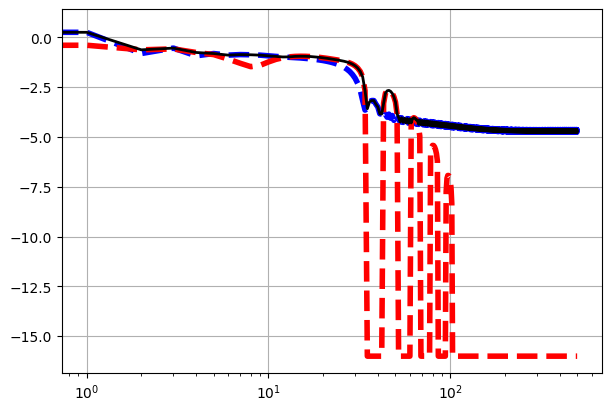

AUC -2162.419809882097/0.7455976694256357 ____ FracWrong:0.07999999999999996, succ AUC 0.17247999999999986 
    tau=0.001      score=  -0.0944  solved=92%  [11.3s]
c = 5;  5x5 = 25 starts on [-2, 2]^2;  500 iterations;  25 runs


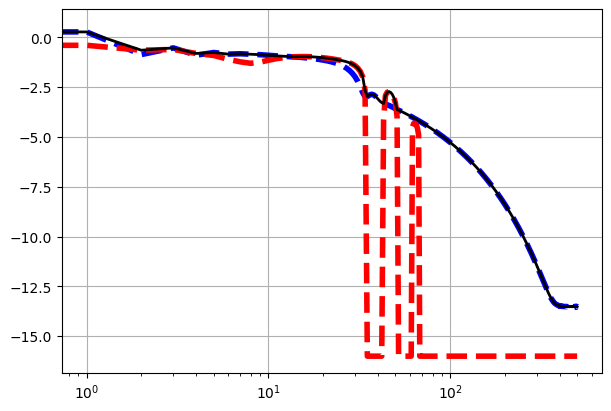

AUC -4600.2016213816305/0.4587998092492199 ____ FracWrong:0.0, succ AUC 0.18600000000000005 
    tau=0.5        score=  -0.5412  solved=100%  [4.0s]
c = 5;  5x5 = 25 starts on [-2, 2]^2;  500 iterations;  25 runs


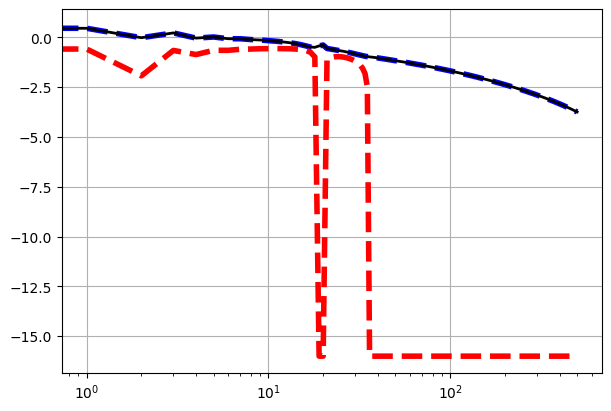

AUC -1234.8852829110597/0.8547193784810518 ____ FracWrong:0.6, succ AUC 0.644 
    tau=10         score=   1.0547  solved=40%  [4.2s]
  → best tau = 0.5   score=-0.5412

  ── Best PABLO params for c=5 ──
    tau         : 0.5   (ref=0.047287, ×10.57)


In [3]:
#test code
PABLO_C10_REF = dict(lr=0.071969, alpha=0.999, eps=1e-9, rho=0.1, lr_lambda=0.1, tau=0.047287, y_rate=0.1, grad_clip=100.0, lambda_bound=10.0, total_steps=None)
        
TUNE_GRIDS = {
    "tau":       [0.001, 0.5,10],
}

def pablo_score(summary):
    """AUC of log10(median |w-w*|). Returns inf if any run diverged."""
    s = summary["PABLO"]
    if s["median_curve_w"] is None:
        return np.inf
    if s["frac_completed"] < 1.0 - 1e-9:   # any divergence → disqualify
        return np.inf
    combined = np.maximum(s["mean_curve_UL_gap"], s["mean_curve_LL_gap"]).clip(min=1e-16)  
    auc = float(np.sum(np.log10(combined)))
    # ----
    fig_c, axes_c = plt.subplots(1, 1, figsize=(6, 4 ), constrained_layout=True)
    log_curve = np.log10(combined)
    axes_c.plot(np.log10(s["mean_curve_UL_gap"].clip(min=1e-16)),'--b', linewidth=4)
    axes_c.grid(True)
    axes_c.plot(np.log10(s["mean_curve_LL_gap"].clip(min=1e-16)),'--r', linewidth=4)
    axes_c.plot(np.log10(combined),'-k', linewidth=2)
    # axes_c.plot(np.log10( s["success_curve"].clip(min=1e-16) ))
    axes_c.grid(True)
    axes_c.set_xscale('log')
    plt.show()
    # ----
    ref_auc = 17*len(combined) #assume values range between 1e-16 and 1e1
    frac_wrong = 1.0 - s["frac_solved"]         
    norm_auc = auc/ref_auc            
    succ_auc = 1-np.sum(s["success_curve"])/len(combined)  
    print(f'AUC {auc}/{1+auc/ref_auc} ____ FracWrong:{1.0 - s["frac_solved"]}, succ AUC {succ_auc} ' )
    return norm_auc+ 2*frac_wrong   

BEST_PABLO = {}   # keyed by c

_T_ITERS = 500
_T_N     = 5
_T_JOBS  = max(1, (os.cpu_count() or 2) - 1)
_GRID_LO, _GRID_HI = [-2,2]
_TOL = 1e-6

for c in [5]:
    print(f"\n{'='*62}\nTuning PABLO   c={c:g}\n{'='*62}")
    best = dict(PABLO_C10_REF)

    for param, grid in TUNE_GRIDS.items():
        print(f"\n  {param}   range [{grid[0]:.4g} … {grid[-1]:.4g}]")
        best_score, best_val = np.inf, best[param]

        print(param, grid)
        for val in grid:
            hp   = {**best, param: float(val)}
            t0   = time.time()
            sw   = run_sweep({"PABLO": hp}, c=c,
                             grid_lo=_GRID_LO, grid_hi=_GRID_HI, grid_n=_T_N,
                             n_iters=_T_ITERS, seed=0, n_jobs=_T_JOBS)
            summ = summarise(sw, tol=_TOL, c=c)
            sc   = pablo_score(summ)
            solved_pct = summ["PABLO"]["frac_solved"] * 100
            tag  = (f"score={sc:9.4f}  solved={solved_pct:.0f}%"
                    if np.isfinite(sc) else "DIVERGED/FAILED     ")
            print(f"    {param}={val:<10.5g} {tag}  [{time.time()-t0:.1f}s]")
            if sc < best_score:
                best_score, best_val = sc, float(val)

        best[param] = best_val
        print(f"  → best {param} = {best_val:.5g}   score={best_score:.4f}")

    BEST_PABLO[c] = dict(best)
    print(f"\n  ── Best PABLO params for c={c:g} ──")
    for k in TUNE_GRIDS:
        ref = PABLO_C10_REF[k]
        print(f"    {k:12s}: {best[k]:.5g}   (ref={ref:.5g}, ×{best[k]/ref:.2f})")